# TSFS12 Hand-in exercise 5: Data-Driven Motion Prediction

**Windows setup:** Start with `start-trajectory-lab.ps1` in the repository root and select **Python (HI5 Trajectory)**. The local environment and course data are installed. See [SETUP.md](SETUP.md) for details; the generic Linux installation examples below are not needed for this setup.

This exercise utilizes data from the SIND dataset to train a deep neural network for motion prediction. The dataset consists of several scenarios with various agents moving about different signalized intersections (see images below). The goal is to predict the future positions of the agents based on their past positions and velocities, taking agent-to-agent interactions into account. Current version of the prediction models uses 3 seconds of historical data and targets predicting up to 5 seconds of future trajectories. Data is recorded at 5 Hz.

This exercise relies heavily on Python and PyTorch libraries. For the basic parts of this exercise, you are not expected to have any prior knowledge of either Python or PyTorch. However, you are encouraged to explore the documentation of these libraries to gain a deeper understanding of the code if you have the required prior knowledge. You will be provided with a set of pre-trained models, and your task is to evaluate and experiment with the models on a test set and analyze and discuss the results.

The data used are real recorded data from 3 densely trafficked intersections in China described in *SIND: A Drone Dataset at Signalized Intersection in China*: https://arxiv.org/abs/2209.02297.

<div style="text-align: center;">
    <img src="media/Chongqing_NR.png" alt="Chongqing_NR" style="width: 30%;">
    <img src="media/Changchun_Pudong.png" alt="Chongqing_NR"style="width: 30%;">
    <img src="media/Xi'an_Shanglin.png" alt="Chongqing_NR" style="width: 30%;">
</div>

The data is preprocessed for you to facilitate this exercise. All preprocessing was done using the *Dronalize* toolbox: https://github.com/westny/dronalize toolbox.

If you are running this notebook from the university linux-labs, the data is directly available (more instructions below). If you are running from your own computer, the preprocessed data can be downloaded from the Lisam course page. The full raw data is available at https://github.com/SOTIF-AVLab/SinD.

If you install on your own computer, some of the packages require specifications specific to your machine.
* https://pytorch.org/get-started/locally/
* https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html
* https://github.com/rusty1s/pytorch_cluster

Follow the instructions for each package

In addition, you will need to install the pure python-packages
* torchinfo
* lightning

For example, to install on a Linux-machine with CPU (no GPU), the following commands installs the required packages
```
# PyTorch
pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu
# PyTorch Geometric
pip install torch_geometric
# PyTorch Cluster
pip install torch-cluster -f https://data.pyg.org/whl/torch-2.8.0+cpu.html
pip install torchinfo lightning
```

### Initial imports
First, some initial imports from used libraries (might take some extra time the first time when caching).

In [1]:
from pathlib import Path
import sys

# Support launching from either the repository root or the notebook folder.
lab_dir = Path.cwd()
if not (lab_dir / "trajectory_prediction" / "utils.py").is_file():
    lab_dir = lab_dir / "HI5-Learning" / "python" / "TrajectoryPrediction"
if not (lab_dir / "trajectory_prediction" / "utils.py").is_file():
    raise RuntimeError("Start Jupyter using start-trajectory-lab.ps1 from the repository root.")
sys.path.insert(0, str(lab_dir))
print(f"Python: {sys.executable}")

from argparse import Namespace
import matplotlib.pyplot as plt

import torch
from torchinfo import summary
from lightning.pytorch import seed_everything

from trajectory_prediction.metrics import MinFDE, MinADE, MissRate
from trajectory_prediction.datamodules.dataloader import DroneDataModule
from trajectory_prediction.plot_tools import plot_scenario, plot_heatmap, plot_scenario_map, get_agent_positions
from trajectory_prediction.utils import load_pretrained_model

Python: c:\Users\Soshy\Desktop\Autonomous-Vehicles\.venv-hi5\Scripts\python.exe


Run the command below if you want your plots in external windows, e.g., with the possibility to zoom. Alternatively, skip the line and generate all plots as static images in the notebook. It is recommended during exploration, since then you can interact and zoom with the plots.

In [2]:
# choose another matplotlib backend for plotting if you want
%matplotlib inline

## 1. Data exploration

When working with data-driven modelling techniques, data-exploration and an understanding of the data is essential. This is often a process that takes considerable time and effort and therefore this is also an important part also in this exercise. 

This section of the exercise will therefore be devoted to loading the data and explore it to get some basic understanding of the data. It is not necessary that you understand all the details of the data, however the more you understand of the data the easier it is to understand what information the predictive models have and understanding the prediction output. 

### 1.1 Load the data

The first step is to load the evaluation data and prepare a data loader to make it easy to iterate through the data. 

Before you begin, set the path to the where the datasets are located. If you do thin in the university Linux-labs, they are located at `/courses/tsfs12/trajectory_prediction/datasets`. If you do this exercise on your own computer, you need to download the datasets from Lisam, there is a zip-file in the Course Documents. The unzipped data is approximately 1.3 GB.

In [3]:
import os

# Optional override for data stored elsewhere.
dataset_path = Path(os.environ.get("HI5_DATASET_PATH", str(lab_dir / "datasets")))
if not (dataset_path / "sinD" / "test").is_dir():
    linux_data = Path("/courses/tsfs12/trajectory_prediction/datasets")
    if linux_data.is_dir():
        dataset_path = linux_data
    else:
        raise FileNotFoundError(
            f"Missing course data: {dataset_path / 'sinD' / 'test'}. "
            "Download hi5_trajectorydata.zip from Lisam Course documents, "
            "then run import_course_data.py with the ZIP path. See SETUP.md."
        )
print(f"Dataset: {dataset_path}")


Dataset: c:\Users\Soshy\Desktop\Autonomous-Vehicles\HI5-Learning\python\TrajectoryPrediction\datasets


Prepare the data loaders.

In [4]:
seed = 42 # A random seed is set so that all environments gives the same results. Do not change the value 42 (at least not in a first run).
seed_everything(42)

# Define the step size 0.2 seconds per sample
STEP_SIZE = 0.2

# Create the datamodule and load the data
config = {
    "root": dataset_path,
    "batch_size": 32,
    "transform": "CoordinateTransform",
    "name": "sinD",
}
args = Namespace(
    small_ds=False,
    num_workers=0,
    pin_memory=False,
    persistent_workers=False,
    seed=seed,
    eval_only=True,
)
dm = DroneDataModule(config, args)
dm.setup()

# Get the test dataloader
loader = dm.test_dataloader()
print(f"Data is loaded and there are {len(loader)} batches in the test dataset")

Seed set to 42


Data is loaded and there are 279 batches in the test dataset


### 1.2 What is in a batch of data?

As seen above, the test data consists of a set of _batches_ and each batch consists of a set of _scenarios_. In this case each batch consists of 32 scenarios. A single batch is represented using a `HeteroDataBatch` object from the [PyTorch Geometric](https://pytorch-geometric.readthedocs.io/) library, built for graph-learning applications but is also useful in learning problems where the data points (samples) in our datasets have varying shapes (dimensions). This is true in many motion prediction problems where we typically encounter a variable number of agents present in each scenario. It is not important for the exercise to be familiar with PyTorch Geometric.

A batch object works similarly like a Python dictionary, or a struct in Matlab, meaning we can access specific properties by indexing the object using the corresponding `key`. In this exercise, a typical batch object may look like:

```
HeteroDataBatch(
  rec_id=[32],
  agent={
    num_nodes=885,
    ta_index=[32],
    ids=[32],
    type=[885],
    inp_pos=[885, 15, 2],
    inp_vel=[885, 15, 2],
    inp_acc=[885, 15, 2],
    inp_yaw=[885, 15, 1],
    trg_pos=[885, 25, 2],
    trg_vel=[885, 25, 2],
    trg_acc=[885, 25, 2],
    trg_yaw=[885, 25, 1],
    input_mask=[885, 15],
    valid_mask=[885, 25],
    sa_mask=[885, 25],
    ma_mask=[885, 25],
    batch=[885],
    ptr=[33],
  },
  map_point={
    num_nodes=13088,
    type=[13088],
    position=[13088, 2],
    batch=[13088],
    ptr=[33],
  },
  (map_point, to, map_point)={
    edge_index=[2, 27328],
    type=[27328, 1],
  }
)
```

First, let us get the first batch object in the test set to explain the contents of the data.

In [5]:
generator = iter(loader)
data = next(generator)
data

HeteroDataBatch(
  rec_id=[32],
  agent={
    num_nodes=885,
    ta_index=[32],
    ids=[32],
    type=[885],
    inp_pos=[885, 15, 2],
    inp_vel=[885, 15, 2],
    inp_acc=[885, 15, 2],
    inp_yaw=[885, 15, 1],
    trg_pos=[885, 25, 2],
    trg_vel=[885, 25, 2],
    trg_acc=[885, 25, 2],
    trg_yaw=[885, 25, 1],
    input_mask=[885, 15],
    valid_mask=[885, 25],
    sa_mask=[885, 25],
    ma_mask=[885, 25],
    batch=[885],
    ptr=[33],
  },
  map_point={
    num_nodes=13088,
    type=[13088],
    position=[13088, 2],
    batch=[13088],
    ptr=[33],
  },
  (map_point, to, map_point)={
    edge_index=[2, 27328],
    type=[27328, 1],
  }
)

Before describing the data structure, let's plot one of the scenarios in the first batch. Where you can see a set of vehicles in a specific situation in an intersection. Remember these commands, you will need them later. 

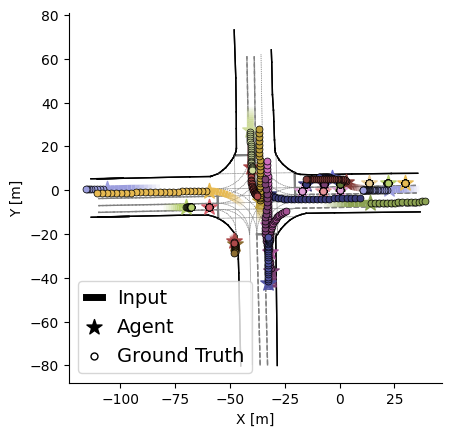

In [6]:
fig, ax = plt.subplots(num=1, clear=True)
plot_scenario(ax, data, highlight_idx=None, scenario_idx=10)

To save a figure to file for inclusion in your report, do
```python
fig.savefig("filename.pdf")
```
to save in PDF format or if you prefer PNG format you instead run
```python
fig.savefig("filename.pdf")
```
The variable `fig` is the one created with the `plt.subplots` command for the figure yoou wanted to save.


Going back to the batch-data, a single object hold several pieces of information, of notable interest is the contents of the property "`agent`". If you index `data` with the key `agent` as
```python
data['agent']
```
it will return a nested dictionary that can be similarly accessed as its parent by using a key, e.g., using `inp_pos`, `inp_vel`, and so on.

This object holds information on the input (preceeded by `inp_`) and target (preceeded by `trg_`) features of the agents in each scenario. Note that each feature is three-dimensional, e.g., `inp_pos`  have shape `(N, T, 2)`.
Here, `N` refers to the total number of agents in the batch, which is the sum of all agents across all scenes in the batch, `T=15` is the length of the input sequence, and final dimension represents positions in 2D (x, y coordinates). 

The sampling time is $0.2$ s and since the input and target are 15 and 25 samples respectively, this corresponds to $3$ and $5$ seconds respectively.


In [7]:
print(f"Number of vehicles in total for all scenarios in the batch: {data['agent']['num_nodes']}")

Number of vehicles in total for all scenarios in the batch: 885


To get the input to the prediction for the first vehicle in the first batch (index 0), run the command below extracting the `inp_pos` property. You will get 15 pairs of (x, y) coordinates, and since the sampling rate is 0.2s this corresponds to 3 seconds of historical data. To get the corresponding for velocity and acceleration extract the `inp_vel` or `inp_acc` properties. There are also `trg_pos`, `trg_vel`, `trg_acc` for the prediction targets, i.e., 5 seconds of pos/vel/acc following the input.

In [8]:
data['agent']['inp_pos'][0]

tensor([[-0.0073,  0.0060],
        [-0.0007, -0.0033],
        [ 0.0209, -0.0038],
        [ 0.0451, -0.0062],
        [ 0.0730, -0.0060],
        [ 0.0834, -0.0035],
        [ 0.0769,  0.0017],
        [ 0.0554,  0.0039],
        [ 0.0313,  0.0043],
        [ 0.0260,  0.0047],
        [ 0.0237,  0.0061],
        [ 0.0042,  0.0069],
        [-0.0079,  0.0053],
        [-0.0096,  0.0027],
        [ 0.0000,  0.0000]])

A very important key-value pair in the `agent` dictionary is `batch`. The contents of 
```python
data['agent']['batch']
```
indicate which agents belong to the same scenario. In our current configuration, we use a batch size of 32, meaning that each batch includes 32 unique scenarios from our test set. This means that `data['agent']['batch']` contains integers from 0 to 31 which can be used to map the agent features to the correct scenario. 
To see this in practice, create a boolean mask to get all the indices that belong to scenario 0 using the command below. The number of vehicles in a scenario are the number of vehicles present during the 3 + 5 second time-window.


In [9]:
mask = (data['agent']['batch'] == 0)
print(f"The number of vehicles in scenario 0: {mask.sum()}")

The number of vehicles in scenario 0: 20


We can use this boolean mask to slice our data and extract features that belong to scenario 0 as:

In [10]:
inp_pos_first_scenario = data['agent']['inp_pos'][mask]
trg_pos_first_scenario = data['agent']['trg_pos'][mask]
print(inp_pos_first_scenario.shape, trg_pos_first_scenario.shape)

torch.Size([20, 15, 2]) torch.Size([20, 25, 2])


### 1.3 Map features
We also note that there is map information in the form of lane graphs for each scenario representing the road network. This is here primarily used for visualization purposes, but two of the used models encode also the map information and utilizes that when making trajectory predictions.


The following code illustrate how you can plot scenarios, in a 2 x 2 grid, to show data in the test set.

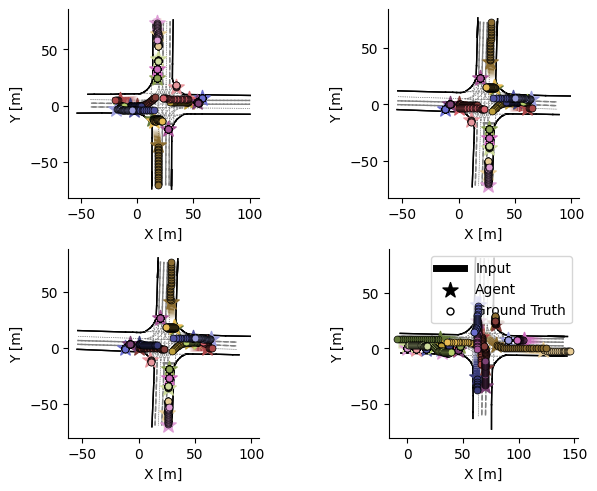

In [11]:
# %% Plot 4 scenarios in the first batch
scenarios_to_plot = [0, 1, 2, 4]  # 32 scenarios in a batch
fig, ax = plt.subplots(2, 2, num=10, clear=True, layout="constrained")
for k, scenario_idx in enumerate(scenarios_to_plot):
    mask = data["agent"]["batch"] == scenario_idx
    inp_pos = data["agent"]["inp_pos"][mask]

    r, c = k // 2, k % 2
    plot_scenario(ax[r, c], data, highlight_idx=None, scenario_idx=scenario_idx)
    ax[r, c].legend().remove()
_ = ax[1, 1].legend()


### 1.4 Questions on the data exploration

To verify you understand the data structure, know how to access specific agent features, a few control questions:

- How many batches and how many scenarios are there in total in the test dataset?
- How many agents are present in the first batch (already available in the variable `data`)?
- How many agents are present in scenario 1 and 2 respectively in the first batch?
- How many different agent types can you find in the batch (look at the `type` key)?
- Extract the target (ground truth) positions for the first agent in the data batch (similar as was done for the input positions earlier).
- Determine how many vehicles are involved in scenario 20 in the first batch.

In [ ]:
# Answers to the data exploration questions (scenario indices start at 0).
data = next(iter(loader))  # Always use the first batch
agents = data["agent"]

print("Batcher:", len(loader))
print("Scenarier totalt:", len(loader.dataset))
print("Agenter i första batchen:", agents["num_nodes"])

for scenario_idx in [1, 2, 20]:
    count = (agents["batch"] == scenario_idx).sum().item()
    print(f"Agenter i scenario {scenario_idx}: {count}")

types = torch.unique(agents["type"])
print("Antal agenttyper:", types.numel())
print("Typkoder:", types.tolist())

target_positions = agents["trg_pos"][0]
print("Första agentens target-positioner:")
print(target_positions)
print("Target-form:", target_positions.shape)


To illustrate data available for prediction for one single vehicle, let's plot the history and target trajectory for agents with idx 12 and 20 in scenario 10 in the first batch. Here the `get_agent_positions` function is used to extract positional data.

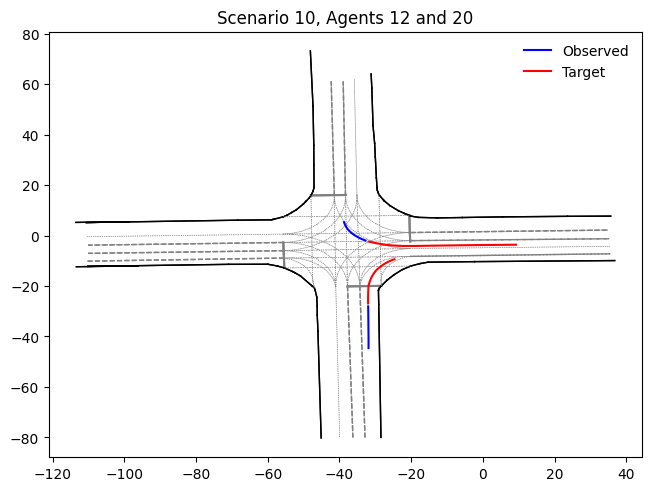

In [12]:
scenario_idx = 10

scenario_mask = data["agent"]["batch"] == scenario_idx
inp_pos_12, trg_pos_12 = get_agent_positions(data, scenario_idx, 12)
inp_pos_20, trg_pos_20 = get_agent_positions(data, scenario_idx, 20)

_, ax = plt.subplots(num=1, clear=True, layout="constrained")
plot_scenario_map(ax, data, scenario_idx)
ax.plot(inp_pos_12[:, 0], inp_pos_12[:, 1], label="Observed", color="blue")
ax.plot(trg_pos_12[:, 0], trg_pos_12[:, 1], label="Target", color="red")
ax.plot(inp_pos_20[:, 0], inp_pos_20[:, 1], color="blue")
ax.plot(trg_pos_20[:, 0], trg_pos_20[:, 1], color="red")
ax.set_title(f"Scenario {scenario_idx}, Agents 12 and 20")
_ = ax.legend(frameon=False)

The `plot_scenario` function has an argument `highlight_idx` that is useful to highlight particular agents/vehicles in a given scenario. For example, the code below plots all vehicles in scenario 10, and highlight agents with idx (20, 12, 15).

Experiment with different scenarios and `highlight_idx` to find interesting cases. (It might be easier if you plot in an external window and use the zoom functionality).

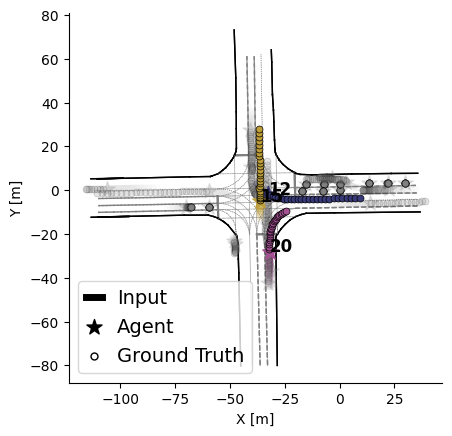

In [13]:
agent_idx = 20
_, ax = plt.subplots(num=2, clear=True)
plot_scenario(ax, data, highlight_idx=[agent_idx, 12, 15], scenario_idx=scenario_idx)

### 1.5 Scenario exploration: history and ground truth

Scenario 10 highlights agents **12 and 20**. The additional example is **scenario 16, agent 2**.
Each figure shows the surrounding traffic, the selected trajectories, and their speed over time.
Solid lines show history; dashed lines show the **recorded future, not a model prediction**.
The star marks the last observed position. Scenario and agent indices start at zero.

Run the following cell after the data-loading cells. Change the scenario and `highlight_idx`
in the two `explore_scenario(...)` calls to explore more cases.
For interactive zoom, run `%matplotlib widget` in a separate cell before this cell.


Scenario 10, agent 12: mean speed 4.51 -> 10.00 m/s; heading change +42.4 degrees
Scenario 10, agent 20: mean speed 6.30 -> 4.25 m/s; heading change -56.2 degrees


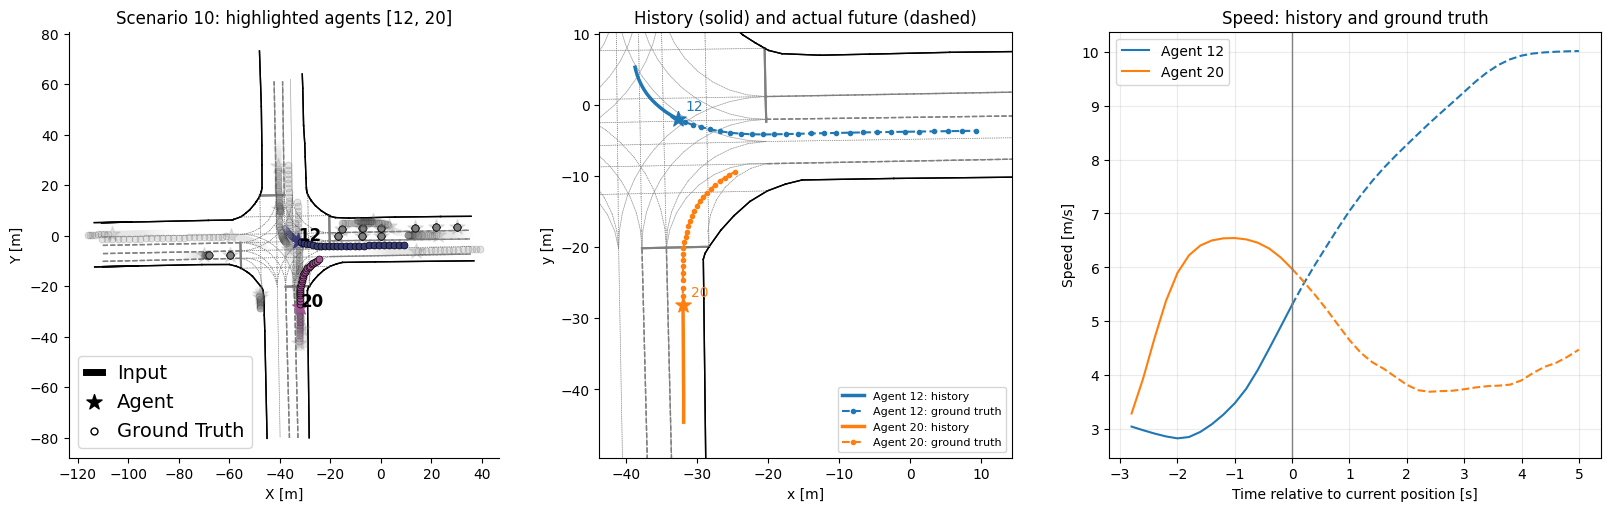

Scenario 16, agent 2: mean speed 5.93 -> 9.27 m/s; heading change -82.3 degrees


In [ ]:

# Explore scenario 10 and an additional turning example

import numpy as np

exploration_data = next(iter(loader))

figure_dir = lab_dir / "exploration_figures"
figure_dir.mkdir(exist_ok=True)


def explore_scenario(scene, highlight_idx, figure_number):
    agents = exploration_data["agent"]

    # Find all agents belonging to the selected scenario
    global_indices = torch.where(agents["batch"] == scene)[0]

    # Create three plots
    fig, axes = plt.subplots(
        1, 3,
        num=figure_number,
        clear=True,
        figsize=(16, 5),
        layout="constrained"
    )

    plot_scenario(
        axes[0],
        exploration_data,
        scenario_idx=scene,
        highlight_idx=highlight_idx
    )
    axes[0].set_title(f"Scenario {scene}: highlighted agents {highlight_idx}")

    plot_scenario_map(axes[1], exploration_data, scene)

    selected_positions = []
    colors = ["tab:blue", "tab:orange", "tab:green"]

    # Process each selected agent
    for agent_idx, color in zip(highlight_idx, colors):
        g = global_indices[agent_idx]

        # Get positions and masks
        hist = agents["inp_pos"][g].clone()
        future = agents["trg_pos"][g].clone()

        input_mask = agents["input_mask"][g]
        valid_mask = agents["valid_mask"][g]

        hist[~input_mask] = np.nan
        future[~valid_mask] = np.nan

        hist = hist.numpy()
        future = future.numpy()

        selected_positions.extend([hist, future])

        # Plot historical positions
        axes[1].plot(
            hist[:, 0],
            hist[:, 1],
            color=color,
            lw=2.5,
            label=f"Agent {agent_idx}: history"
        )

        # Plot future positions, connected to the last observed position
        joined = np.vstack([hist[-1], future])

        axes[1].plot(
            joined[:, 0],
            joined[:, 1],
            "--o",
            color=color,
            markersize=3,
            label=f"Agent {agent_idx}: ground truth"
        )

        # Mark the current position
        axes[1].scatter(
            *hist[-1],
            color=color,
            marker="*",
            s=130,
            zorder=5
        )

        axes[1].annotate(
            str(agent_idx),
            hist[-1],
            xytext=(6, 6),
            textcoords="offset points",
            color=color
        )

        # Calculate speed from velocity
        hist_speed = agents["inp_vel"][g].norm(dim=-1).numpy().copy()
        future_speed = agents["trg_vel"][g].norm(dim=-1).numpy().copy()

        hist_speed[~input_mask.numpy()] = np.nan
        future_speed[~valid_mask.numpy()] = np.nan

        # Plot historical and future speed
        hist_time = np.arange(-14, 1) * STEP_SIZE
        future_time = np.arange(0, 26) * STEP_SIZE

        axes[2].plot(
            hist_time,
            hist_speed,
            color=color,
            label=f"Agent {agent_idx}"
        )

        axes[2].plot(
            future_time,
            np.r_[hist_speed[-1], future_speed],
            "--",
            color=color
        )

        # Calculate average speed over the last five samples
        before = np.nanmean(hist_speed[-5:])
        after = np.nanmean(future_speed[-5:])

        # Calculate heading change
        v = agents["inp_vel"][g, -5:].mean(0)
        w = agents["trg_vel"][g, -5:].mean(0)

        cross = float(v[0] * w[1] - v[1] * w[0])
        dot = float(v @ w)

        turn = np.degrees(np.arctan2(cross, dot))

        print(
            f"Scenario {scene}, agent {agent_idx}: "
            f"mean speed {before:.2f} -> {after:.2f} m/s; "
            f"heading change {turn:+.1f} degrees"
        )

    # Set plot limits based on selected agents
    points = np.concatenate(selected_positions)
    points = points[np.isfinite(points).all(axis=1)]

    axes[1].set_xlim(points[:, 0].min() - 5, points[:, 0].max() + 5)
    axes[1].set_ylim(points[:, 1].min() - 5, points[:, 1].max() + 5)

    # Format trajectory plot
    axes[1].set_aspect("equal")
    axes[1].set_title("History (solid) and actual future (dashed)")
    axes[1].set_xlabel("x [m]")
    axes[1].set_ylabel("y [m]")
    axes[1].legend(fontsize=8)

    # Format speed plot
    axes[2].axvline(0, color="grey", lw=1)

    axes[2].set(
        xlabel="Time relative to current position [s]",
        ylabel="Speed [m/s]",
        title="Speed: history and ground truth"
    )

    axes[2].grid(alpha=0.25)
    axes[2].legend()

    # Save figures
    fig.savefig(figure_dir / f"scenario_{scene}.png", dpi=160)
    fig.savefig(figure_dir / f"scenario_{scene}.pdf")

    plt.show()

    return fig


# Generate figures for selected scenarios
fig_scenario10 = explore_scenario(10, [12, 20], 101)
fig_scenario16 = explore_scenario(16, [2], 102)

print(f"Figures saved in: {figure_dir}")


**Observations to investigate:**

- **Scenario 10, agent 12:** The path bends counterclockwise (about +42 degrees between the two velocity windows). Mean speed increases from approximately 4.51 to 10.00 m/s.
- **Scenario 10, agent 20:** The path bends clockwise (about -56 degrees). Mean speed decreases from approximately 6.30 to 4.25 m/s.
- **Scenario 16, agent 2:** A pronounced clockwise turn (about -82 degrees) makes this an interesting additional case. Mean speed increases from approximately 5.93 to 9.27 m/s.

Speeds compare the mean speed over the last five history samples with the last five future samples (one-second windows). Heading change compares the average velocity vectors over those same windows; it is not a sum of all turns along the trajectory. The figures show motion, but do not by themselves establish whether another road user caused a speed or direction change.

PNG and PDF copies are saved in **`exploration_figures`**, next to this notebook.


## 2. Inspect the models and make some predictions

Now, let's look at the provided models. There are 4 models provided, 3 neural network models (pre-trained) and 1 simple constant velocity model. The three neural network models are
* Neural Network with no utilization of the map
* Neural Network with map encoder
* Neural Network with a more extensive map encoder, Graph Attention Network (GAT)

### 2.1 Load the models
First, load the pre-trained model and print out some general information.

In [14]:
model_nomap = load_pretrained_model()
_ = model_nomap.eval()  # Set the module in evaluation mode, no training in the assignment
summary(model_nomap.model)

Layer (type:depth-idx)                                  Param #
TrajNet                                                 --
├─Linear: 1-1                                           1,024
├─GRU: 1-2                                              99,072
├─InteractionNet: 1-3                                   --
│    └─MultiheadAttention: 2-1                          49,536
│    │    └─NonDynamicallyQuantizableLinear: 3-1        16,512
├─GRUCell: 1-4                                          50,688
├─Linear: 1-5                                           258
Total params: 217,090
Trainable params: 217,090
Non-trainable params: 0

In [15]:
model_map = load_pretrained_model(extra="map_mpnn")  # Map-based model
_ = model_map.eval()
summary(model_map.model)

Layer (type:depth-idx)                                  Param #
TrajNet                                                 --
├─Linear: 1-1                                           1,024
├─GRU: 1-2                                              99,072
├─InteractionNet: 1-3                                   --
│    └─MultiheadAttention: 2-1                          49,536
│    │    └─NonDynamicallyQuantizableLinear: 3-1        16,512
├─MPNNMapEncoder: 1-4                                   --
│    └─Sequential: 2-2                                  --
│    │    └─GraphConv: 3-2                              640
│    │    └─GELU: 3-3                                   --
│    │    └─GraphConv: 3-4                              16,448
│    │    └─GELU: 3-5                                   --
│    │    └─GraphConv: 3-6                              16,512
│    └─Sequential: 2-3                                  --
│    │    └─Linear: 3-7                                 896
│    │    └─GELU: 3-8     

In [16]:
model_gatmap = load_pretrained_model(extra="map_gat")  # Map-based model
_ = model_gatmap.eval()
summary(model_gatmap.model)

Layer (type:depth-idx)                                  Param #
TrajNet                                                 --
├─Linear: 1-1                                           1,024
├─GRU: 1-2                                              99,072
├─InteractionNet: 1-3                                   --
│    └─MultiheadAttention: 2-1                          49,536
│    │    └─NonDynamicallyQuantizableLinear: 3-1        16,512
├─GATMapEncoder: 1-4                                    --
│    └─Sequential: 2-2                                  --
│    │    └─GATv2Conv: 3-2                              1,792
│    │    └─GELU: 3-3                                   --
│    │    └─GATv2Conv: 3-4                              34,048
│    │    └─GELU: 3-5                                   --
│    │    └─GATv2Conv: 3-6                              34,048
├─Sequential: 1-5                                       --
│    └─Linear: 2-3                                      32,896
│    └─GELU: 2-4     

And also define our constant velocity prediction model.

In [17]:
def constant_velocity(data, N, dt):
    x0 = data["agent"]["inp_pos"][:, -1:]  # Last observed position
    v0 = data["agent"]["inp_vel"][:, -1:]  # Last observed velocity

    t = torch.arange(1, N + 1, device=v0.device) * dt 
    t = t.reshape(1, -1, 1)  # Ensure broadcasting works correctly

    return x0 + v0 * t  # Euler forward

### 2.2 A first prediction
Now, let us make a prediction for all vehicles in a given batch of data using the simplest of the neural network models and plot the result.

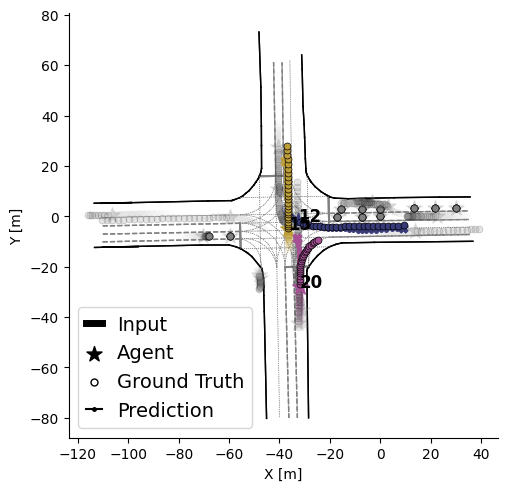

In [18]:
with torch.no_grad():  # Turn of gradients computation
    _, pred, attn, _ = model_nomap(data)

fig, ax = plt.subplots(num=15, clear=True, layout="constrained")
plot_scenario(ax, data, pred, scenario_idx=scenario_idx, highlight_idx=[agent_idx, 12, 15])


Here we've made use of the `highlight_idx` argument, that highligts given agents in the plot for easier illustration.

To get the predicted trajectory of an agent, 

In [19]:
scenario_idx = 10
agent_idx = 20
scenario_mask = data["agent"]["batch"] == scenario_idx

agent_prediction = pred[scenario_mask][agent_idx]  # Get the prediction for the agent
print(f"Matrix with predicted (x,y)-coordinates has dimension {agent_prediction.shape}")

Matrix with predicted (x,y)-coordinates has dimension torch.Size([25, 2])


Below is code for plotting a single agent history, target, and prediction.

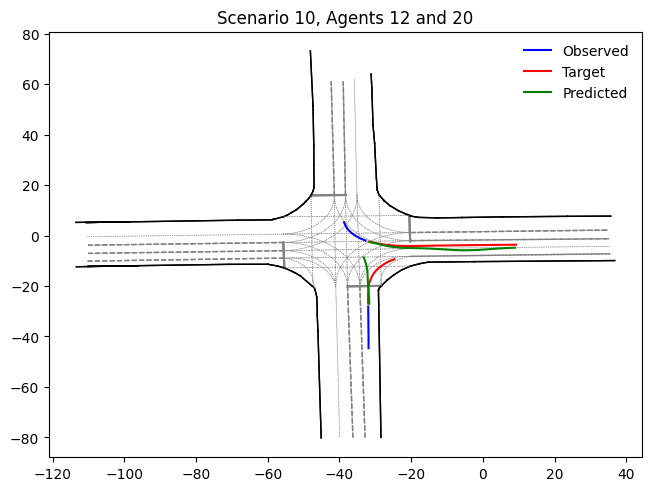

In [20]:
inp_pos, trg_pos = get_agent_positions(data, scenario_idx, agent_idx)

inp_pos_12, trg_pos_12 = get_agent_positions(data, scenario_idx, 12)  
agent_prediction_12 = pred[scenario_mask][12]

fig, ax = plt.subplots(num=15, clear=True, layout="constrained")
plot_scenario_map(ax, data, scenario_idx)
ax.plot(inp_pos[:, 0], inp_pos[:, 1], label="Observed", color="blue")
ax.plot(trg_pos[:, 0], trg_pos[:, 1], label="Target", color="red")
ax.plot(agent_prediction[:, 0], agent_prediction[:, 1], label="Predicted", color="green")

ax.plot(inp_pos_12[:, 0], inp_pos_12[:, 1], color="blue")
ax.plot(trg_pos_12[:, 0], trg_pos_12[:, 1], color="red")
ax.plot(agent_prediction_12[:, 0], agent_prediction_12[:, 1], color="green")

ax.set_title(f"Scenario {scenario_idx}, Agents 12 and {agent_idx}")
_ = ax.legend(frameon=False)



### 2.3 Timing

Run the cells below to time the different methods. Write down the values you get to be used in the report. Note that runtime will vary from machine to machine. Especially if you have GPU support.


In [21]:
%%timeit -n 10 -r 5
with torch.no_grad():  # Turn off gradients computation
    _, pred, _, _ = model_nomap(data)

46.9 ms ± 1.4 ms per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [22]:
%%timeit  -n 10 -r 5
with torch.no_grad():  # Turn off gradients computation
    _, pred, _, _ = model_map(data)

121 ms ± 5.01 ms per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [23]:
%%timeit  -n 10 -r 5
with torch.no_grad():  # Turn off gradients computation
    _, pred, _, _ = model_gatmap(data)

330 ms ± 15 ms per loop (mean ± std. dev. of 5 runs, 10 loops each)


In [24]:
%%timeit  -n 1000 -r 5
cv_pred = constant_velocity(data, 25, STEP_SIZE)

469 μs ± 30.7 μs per loop (mean ± std. dev. of 5 runs, 1,000 loops each)


### 2.4 Questions for the models and prediction section

- Explore the first data batch and find interesting scenarios and agents, use provided code (use the `highlight_idx` parameter). 
    - Start with agents with index 12, 15, and 20 in scenario 10. 
    - Compare the 4 different prediction models and reflect upon the results. 
    - In particular, think about predictions in cases there are several candidate future options, e.g., left-right-straight
    - Think about situations where the constant-velocity model might be expected to work well and where it doesn't.
- Include interesting plots in the report that you found during your exploration.

Inspect the architecture
- How many parameters are in each model, relate to the inference/prediction time.
- Discuss prediction time with respect to a real-time application of the model in a real vehicle. Which models are real-time feasible?
- Optional if you have sufficient python/pytorch experience:
    - How many components does the model consist of and what is the purpose of each component?

### 2.4.1 Executed comparison: predictions, parameters and latency

The following cell compares all four methods on the first batch, highlights agents 12, 15 and 20 in scenario 10, and adds scenario 16 / agent 2. It saves PNG/PDF plots and CSV tables in `model_comparison`. Run the model-loading and constant-velocity cells first.

Timing uses CPU, four PyTorch threads, 3 warmups and 20 repetitions. The previous thread setting is restored afterwards. Single-scene latency is measured directly, not estimated by dividing batch latency. These timings can differ from section 2.3 if its thread settings differ.


CPU: Intel64 Family 6 Model 158 Stepping 10, GenuineIntel; PyTorch 2.4.1+cpu; 4 threads
Batch: 32 scenarios, 885 agents
Single scene 10: 27 agents; 25 predicted steps (5 s)
20 measured calls after 3 warmups; medians and empirical p95 (not worst-case guarantees).

Parameters and latency:
   model  parameters  batch_median_ms  batch_p95_ms  scene10_median_ms  scene10_p95_ms
      CV           0            0.548         0.625              0.106           0.110
  No map      217090           38.554        43.288              4.892           5.662
MPNN map      301123          121.347       144.353              7.074           7.583
 GAT map      336386          306.461       325.493             13.932          15.977

FIRST batch only, notebook ma_mask:
   model  ADE_m  FDE_m
      CV  2.207  5.635
  No map  1.494  3.965
MPNN map  1.358  3.706
 GAT map  1.267  3.412

Selected agents, valid_mask:
 scenario  agent    model  valid_steps  ADE_m  FDE_m
       10     12       CV           25  9.

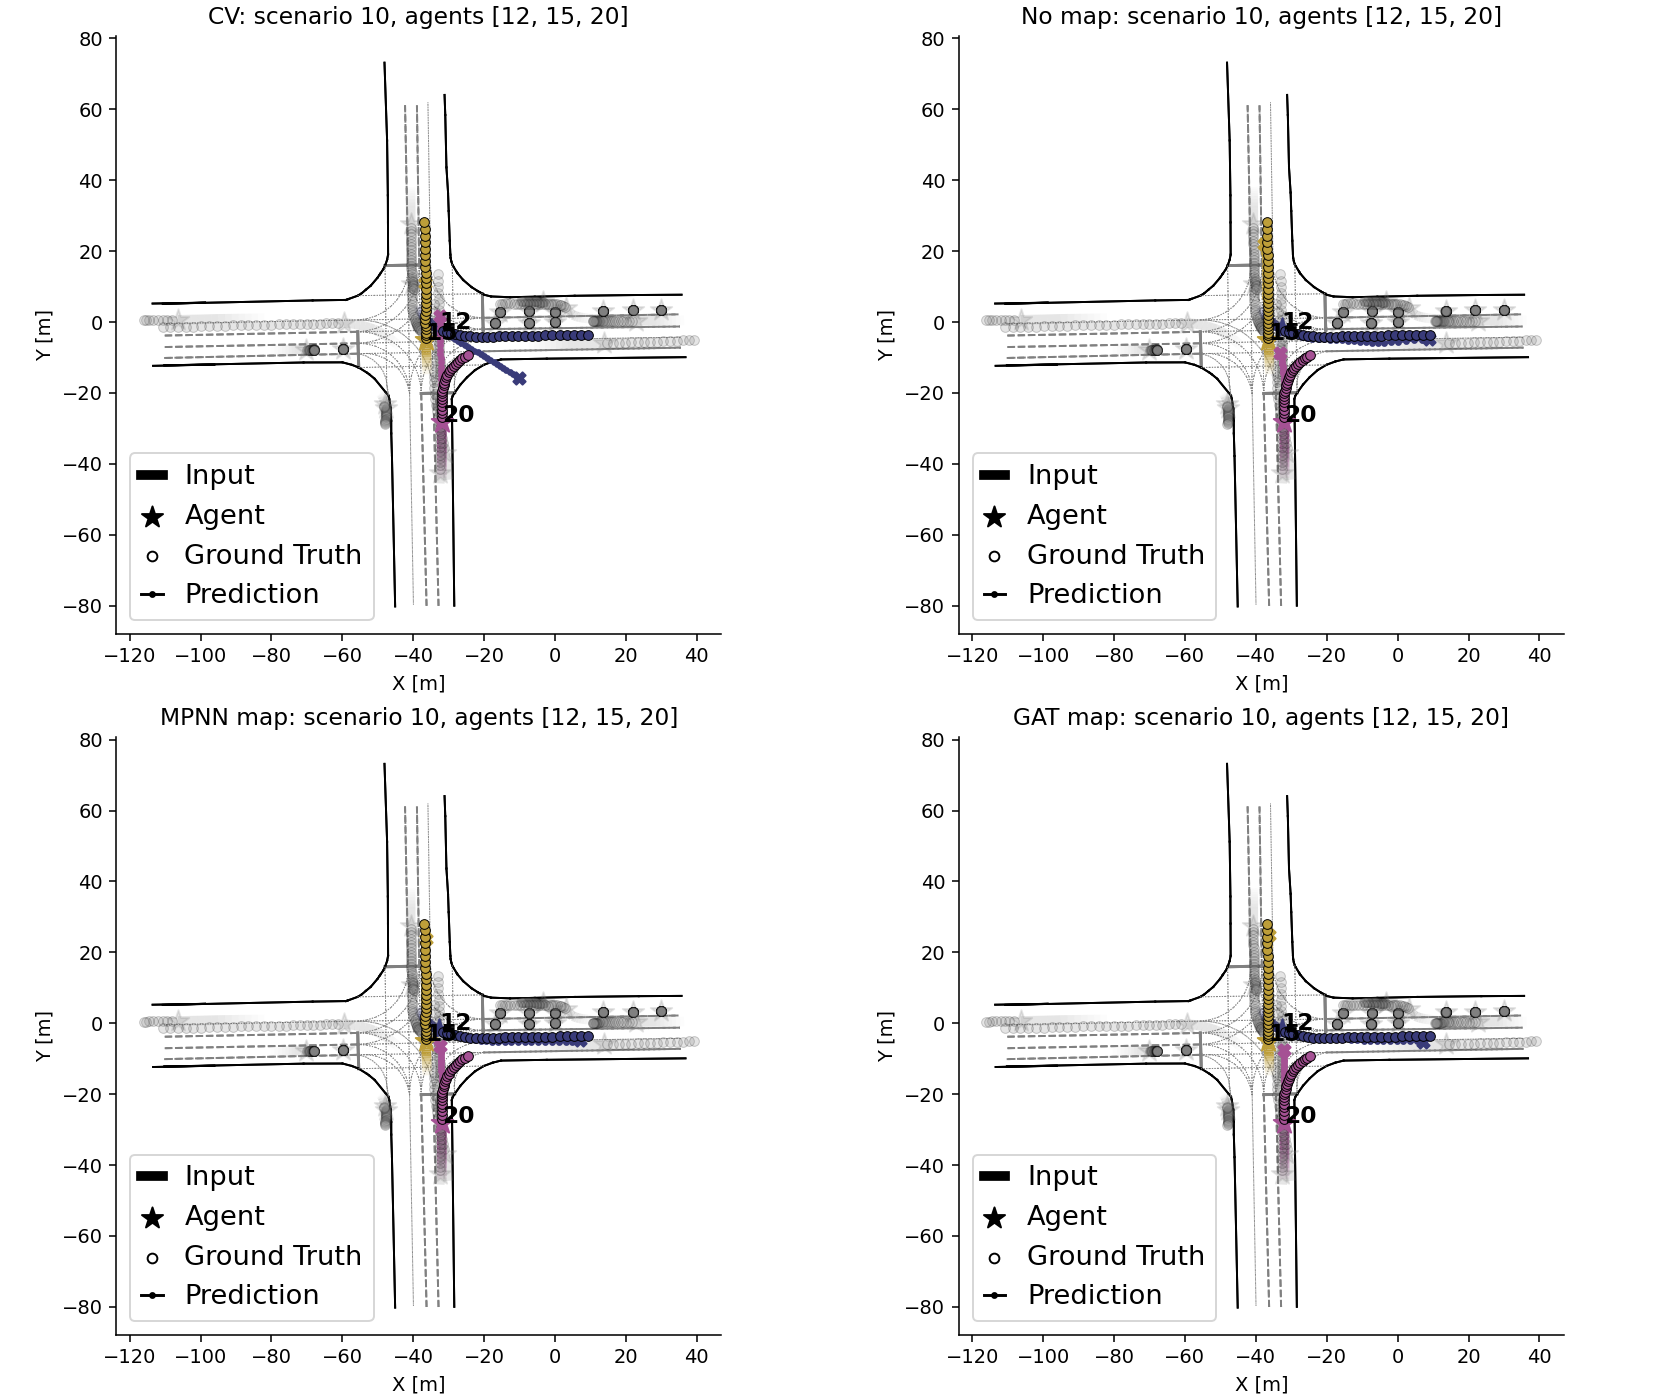

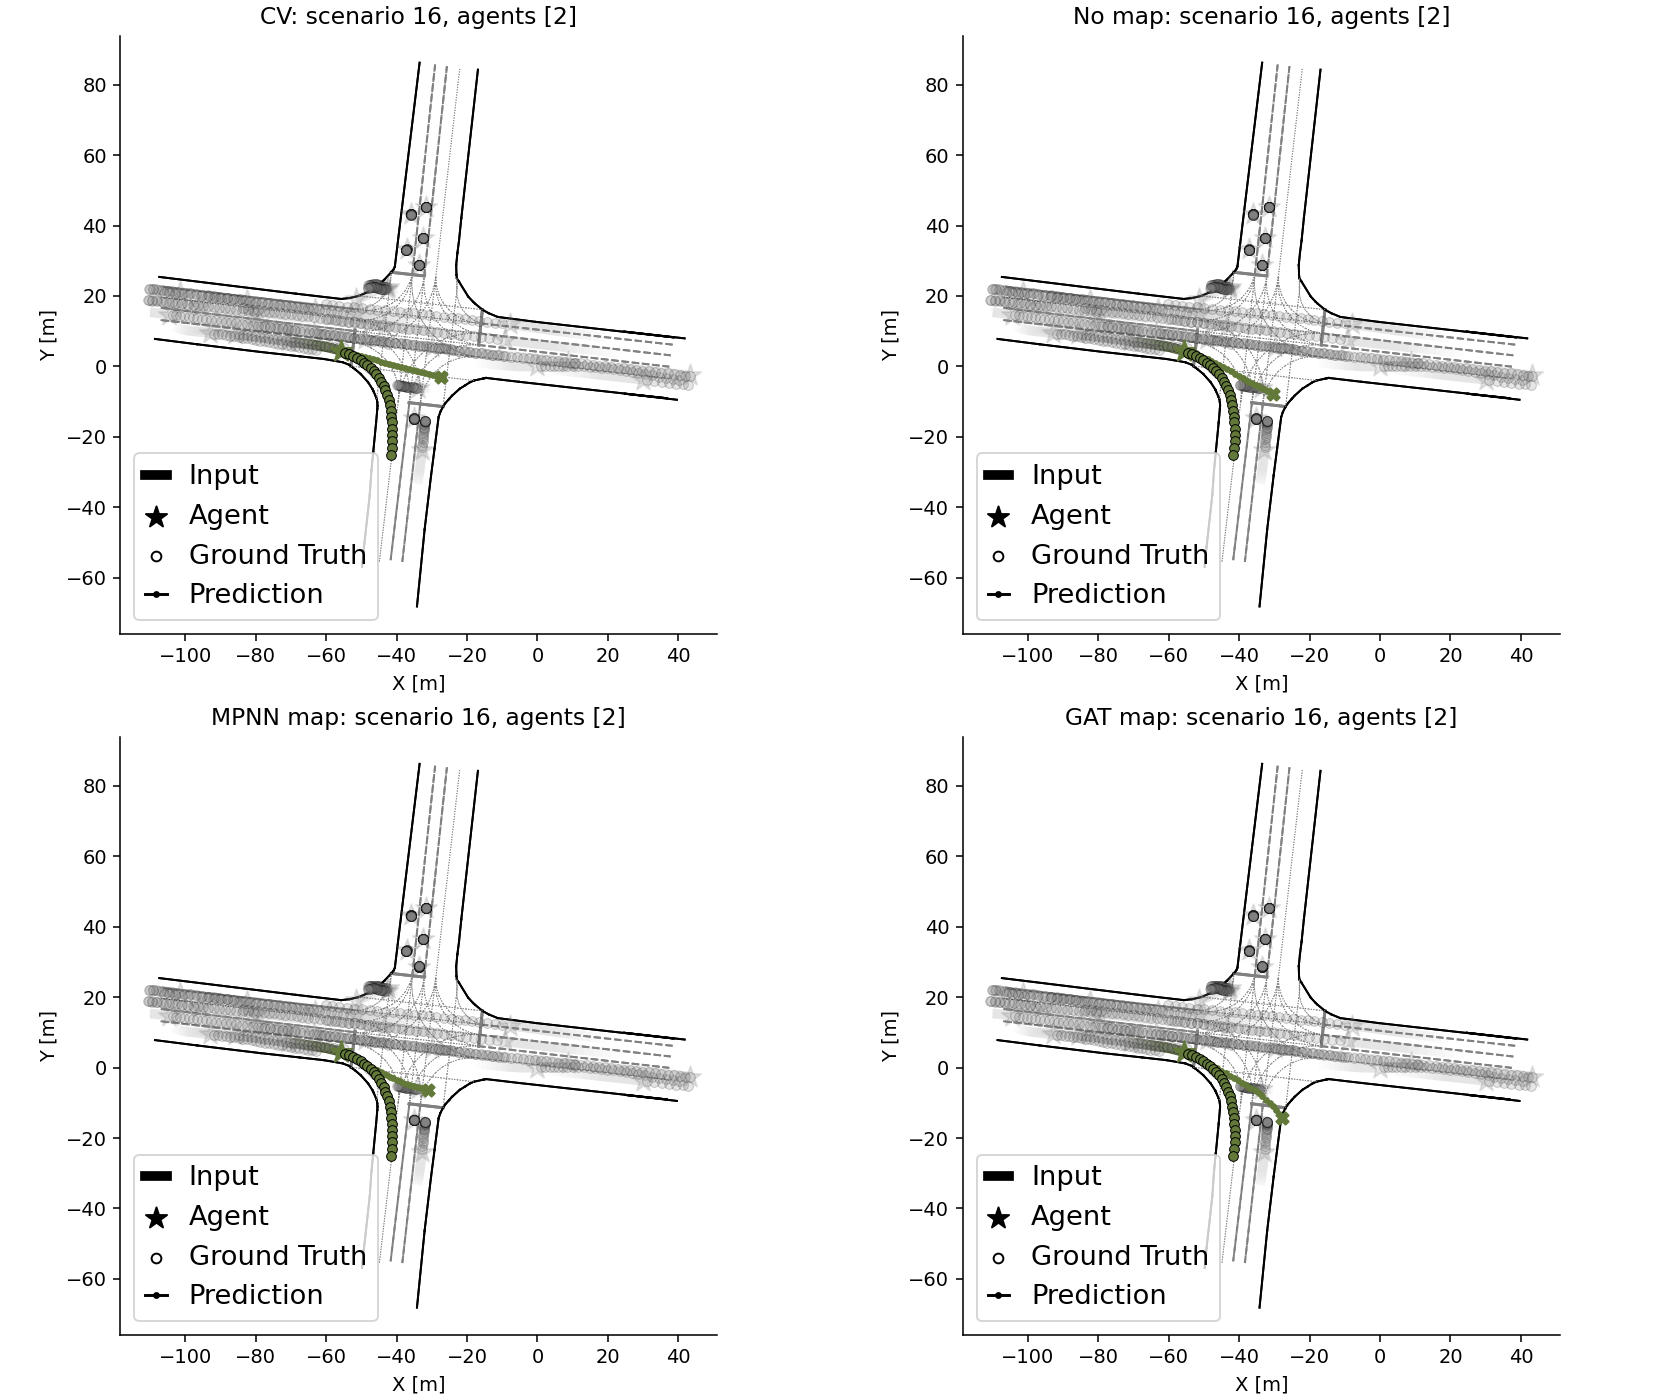

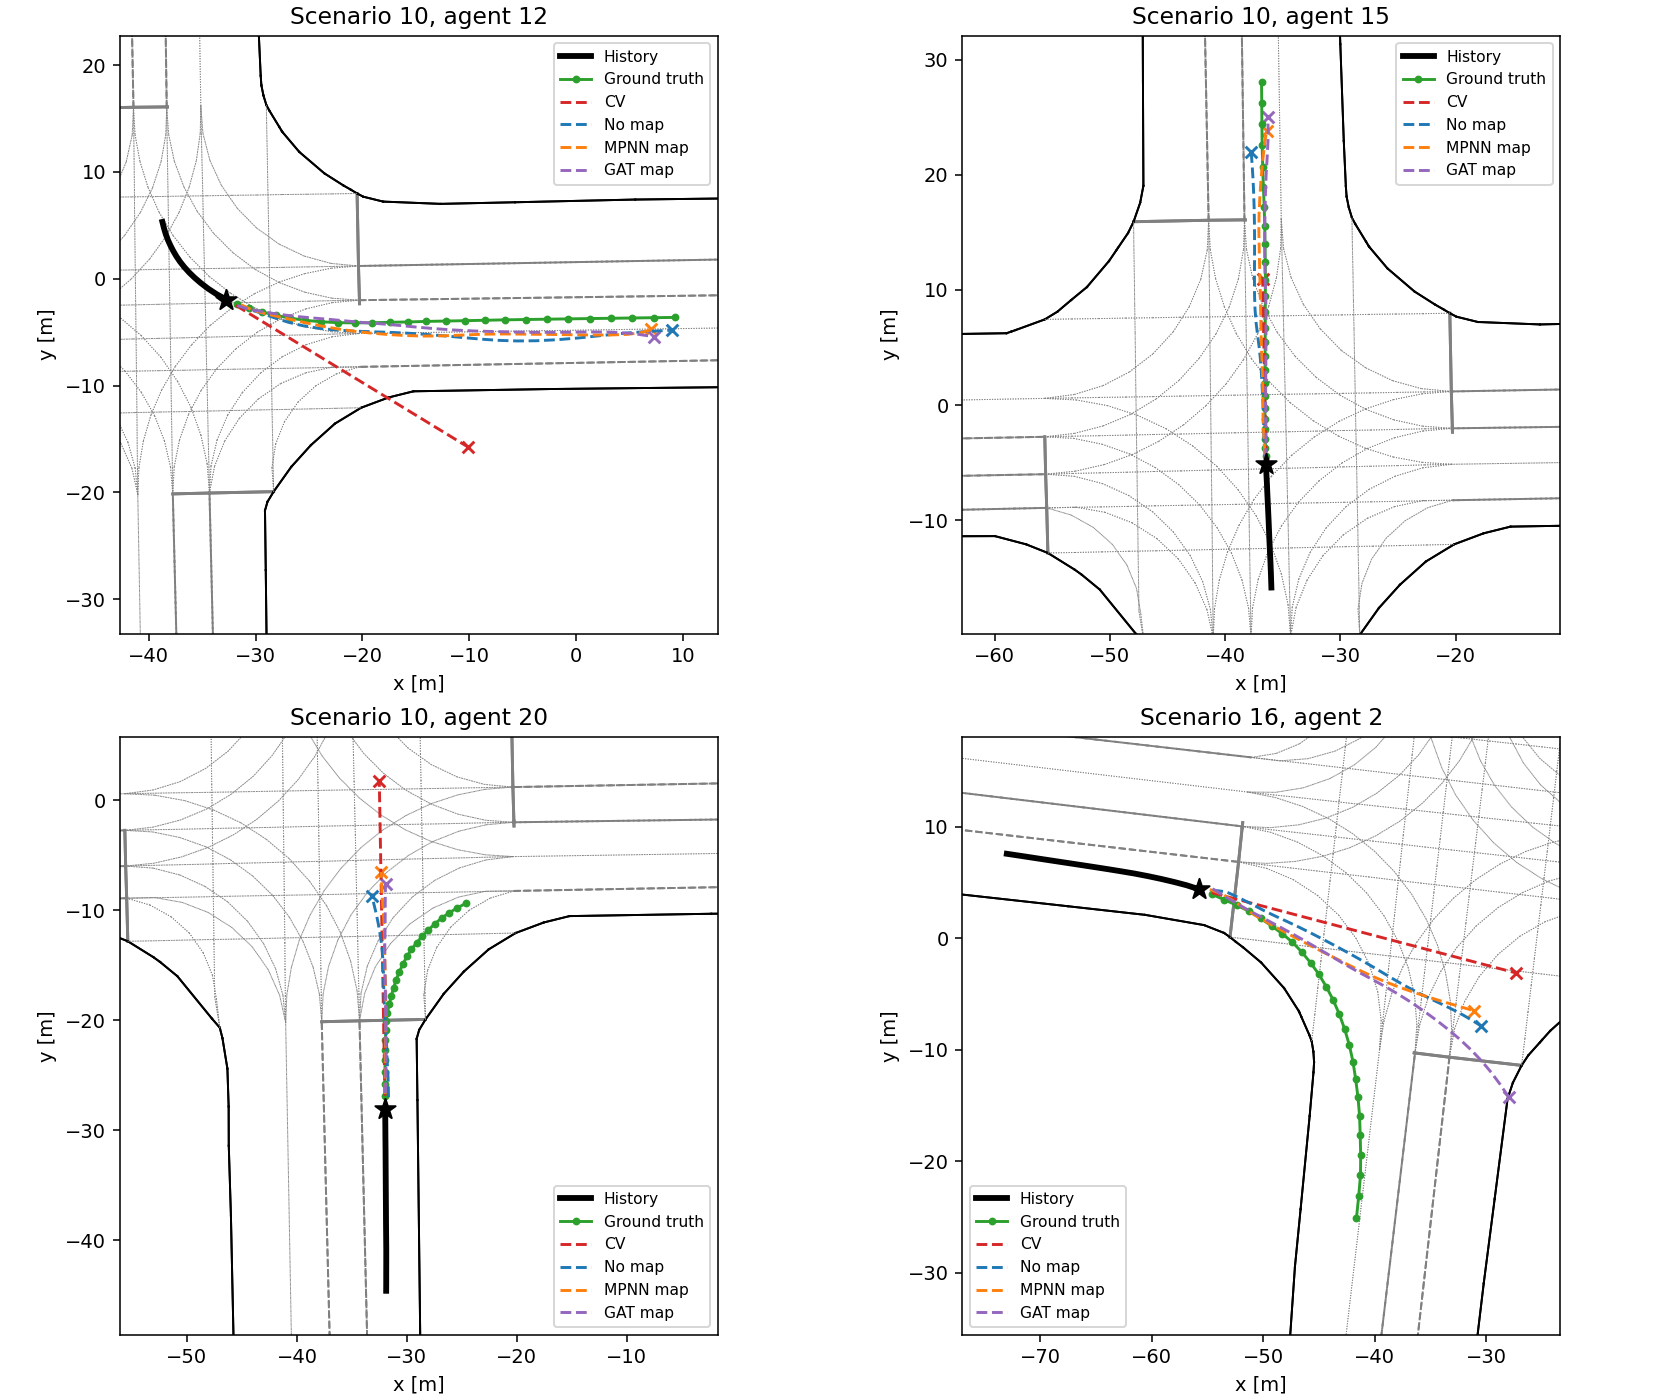

In [ ]:

import time
import platform
import pandas as pd
import numpy as np

from torch_geometric.data import Batch




# Reload the first batch
comparison_data = next(iter(loader)).cpu()

comparison_models = {
    "CV": None,
    "No map": model_nomap.cpu().eval(),
    "MPNN map": model_map.cpu().eval(),
    "GAT map": model_gatmap.cpu().eval()
}

comparison_dir = lab_dir / "model_comparison"
comparison_dir.mkdir(exist_ok=True)




def predict24(name, batch):
    if name == "CV":
        return constant_velocity(batch, 25, STEP_SIZE)

    return comparison_models[name](batch)[1]


def benchmark24(name, batch, repeats=20):
    # Measure CPU inference time in milliseconds
    # Data loading and plotting are excluded

    durations = []

    with torch.no_grad():
        # Warm up the model
        for _ in range(3):
            predict24(name, batch)

        # Measure inference time
        for _ in range(repeats):
            start = time.perf_counter()
            predict24(name, batch)

            elapsed_ms = (time.perf_counter() - start) * 1000
            durations.append(elapsed_ms)

    median = float(np.median(durations))
    p95 = float(np.percentile(durations, 95))

    return median, p95



previous_threads = torch.get_num_threads()
benchmark_threads = 4

timing_rows = []
metric_rows = []
agent_rows = []

comparison_predictions = {}

# Extract scenario 10 as a separate batch
single_scene = Batch.from_data_list(
    [comparison_data.to_data_list()[10]]
)

agents = comparison_data["agent"]

selected_agents = [
    (10, [12, 15, 20]),
    (16, [2])
]



try:
    torch.set_num_threads(benchmark_threads)

    for name, model in comparison_models.items():

        # Generate predictions
        with torch.no_grad():
            prediction = predict24(name, comparison_data)

        # Check prediction shape and values
        assert prediction.shape == agents["trg_pos"].shape
        assert torch.isfinite(prediction).all()

        comparison_predictions[name] = prediction

        # Measure inference time
        batch_ms, batch_p95 = benchmark24(name, comparison_data)
        scene_ms, scene_p95 = benchmark24(name, single_scene)

        # Count model parameters
        parameters = (
            0 if model is None
            else sum(p.numel() for p in model.parameters())
        )

        timing_rows.append({
            "model": name,
            "parameters": parameters,
            "batch_median_ms": batch_ms,
            "batch_p95_ms": batch_p95,
            "scene10_median_ms": scene_ms,
            "scene10_p95_ms": scene_p95
        })

        # Calculate ADE and FDE for the first batch
        ade = MinADE()
        fde = MinFDE()

        ade.update(
            prediction,
            agents["trg_pos"],
            mask=agents["ma_mask"]
        )

        fde.update(
            prediction,
            agents["trg_pos"],
            mask=agents["ma_mask"]
        )

        metric_rows.append({
            "model": name,
            "ADE_m": float(ade.compute()),
            "FDE_m": float(fde.compute())
        })

        # Calculate errors for selected agents
        for scene, agent_ids in selected_agents:

            scene_indices = torch.where(
                agents["batch"] == scene
            )[0]

            for agent_id in agent_ids:
                global_idx = scene_indices[agent_id]

                mask = agents["valid_mask"][global_idx].bool()

                errors = (
                    prediction[global_idx]
                    - agents["trg_pos"][global_idx]
                ).norm(dim=-1)[mask]

                agent_rows.append({
                    "scenario": scene,
                    "agent": agent_id,
                    "model": name,
                    "valid_steps": int(mask.sum()),
                    "ADE_m": float(errors.mean()),
                    "FDE_m": float(errors[-1])
                })

finally:
    # Restore original number of threads
    torch.set_num_threads(previous_threads)



# 5. Display and savee


timings24 = pd.DataFrame(timing_rows)
metrics24 = pd.DataFrame(metric_rows)
agents24 = pd.DataFrame(agent_rows)

print(
    f"CPU: {platform.processor()}; "
    f"PyTorch {torch.__version__}; "
    f"{benchmark_threads} threads"
)

print(
    f"Batch: {comparison_data.num_graphs} scenarios, "
    f"{agents.num_nodes} agents"
)

print(
    f"Single scene 10: {single_scene['agent'].num_nodes} agents; "
    "25 predicted steps (5 s)"
)

print(
    "20 measured calls after 3 warmups; "
    "medians and empirical p95 (not worst-case guarantees)."
)

number_format = lambda x: f"{x:.3f}"

print(
    "\nParameters and latency:\n"
    + timings24.to_string(
        index=False,
        float_format=number_format
    )
)

print(
    "\nFIRST batch only, notebook ma_mask:\n"
    + metrics24.to_string(
        index=False,
        float_format=number_format
    )
)

print(
    "\nSelected agents, valid_mask:\n"
    + agents24.to_string(
        index=False,
        float_format=number_format
    )
)

timings24.to_csv(
    comparison_dir / "timings.csv",
    index=False
)

metrics24.to_csv(
    comparison_dir / "batch_metrics.csv",
    index=False
)

agents24.to_csv(
    comparison_dir / "agent_metrics.csv",
    index=False
)


#6

comparison_figures = []

for scene, agent_ids in selected_agents:

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 10),
        layout="constrained"
    )

    for ax, (name, prediction) in zip(
        axes.flat,
        comparison_predictions.items()
    ):
        plot_scenario(
            ax,
            comparison_data,
            prediction,
            scenario_idx=scene,
            highlight_idx=agent_ids
        )

        ax.set_title(
            f"{name}: scenario {scene}, agents {agent_ids}"
        )

    path = comparison_dir / f"scenario_{scene}_four_models"

    fig.savefig(path.with_suffix(".png"), dpi=140)
    fig.savefig(path.with_suffix(".pdf"))

    comparison_figures.append(path.with_suffix(".png"))

    plt.show()



# 7. Create closeup plots for selected agents


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    layout="constrained"
)

model_colors = {
    "CV": "tab:red",
    "No map": "tab:blue",
    "MPNN map": "tab:orange",
    "GAT map": "tab:purple"
}

closeup_agents = [
    (10, 12),
    (10, 15),
    (10, 20),
    (16, 2)
]

for ax, (scene, agent_id) in zip(axes.flat, closeup_agents):

    # Find the selected agent
    scene_indices = torch.where(
        agents["batch"] == scene
    )[0]

    global_idx = scene_indices[agent_id]

    # Get valid history and future positions
    history = agents["inp_pos"][global_idx][
        agents["input_mask"][global_idx]
    ].numpy()

    target = agents["trg_pos"][global_idx][
        agents["valid_mask"][global_idx]
    ].numpy()

    # Plot the map
    plot_scenario_map(ax, comparison_data, scene)

    # Plot observed history
    ax.plot(
        history[:, 0],
        history[:, 1],
        color="black",
        lw=3,
        label="History"
    )

    # Plot ground truth
    ax.plot(
        target[:, 0],
        target[:, 1],
        "o-",
        color="tab:green",
        markersize=3,
        label="Ground truth"
    )

    # Mark the current position
    ax.scatter(
        *history[-1],
        marker="*",
        s=120,
        color="black",
        zorder=10
    )

    all_positions = [history, target]

    # Plot predictions from all four models
    for name, prediction in comparison_predictions.items():

        predicted_positions = prediction[global_idx].numpy()
        all_positions.append(predicted_positions)

        ax.plot(
            predicted_positions[:, 0],
            predicted_positions[:, 1],
            "--",
            color=model_colors[name],
            label=name
        )

        ax.scatter(
            *predicted_positions[-1],
            marker="x",
            color=model_colors[name]
        )

    # Adjust plot limits
    all_positions = np.concatenate(all_positions)

    center = (
        all_positions.min(axis=0)
        + all_positions.max(axis=0)
    ) / 2

    half_width = max(
        np.ptp(all_positions[:, 0]),
        np.ptp(all_positions[:, 1])
    ) / 2 + 4

    ax.set_xlim(
        center[0] - half_width,
        center[0] + half_width
    )

    ax.set_ylim(
        center[1] - half_width,
        center[1] + half_width
    )

    # Format plot
    ax.set_aspect("equal")
    ax.set_title(f"Scenario {scene}, agent {agent_id}")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(fontsize=8)



path = comparison_dir / "selected_agents_closeup"

fig.savefig(path.with_suffix(".png"), dpi=140)
fig.savefig(path.with_suffix(".pdf"))

comparison_figures.append(path.with_suffix(".png"))

plt.show()


### 2.4.2 Results and interpretation

These are observations from the executed first-batch comparison, not a full-test-set ranking.

**Selected agents and model behavior**

- **Scenario 10, agent 12:** The agent completes a turn and accelerates. CV extends the current velocity along a straight line and misses the continuation. All neural models follow the turn much better. MPNN has the smallest ADE (1.08 m); No map has the smallest final error (1.24 m). Thus map information does not improve every metric for every agent.
- **Scenario 10, agent 15:** The path is approximately straight, but speed rises from 3.22 m/s at the last observed sample to 9.25 m/s at the last future sample. CV gets the general direction right but predicts too little progress. GAT has the lowest ADE/FDE here (1.01/3.12 m), compared with CV (6.19/17.12 m).
- **Scenario 10, agent 20:** The actual future bends right while the predictions continue approximately straight. GAT is the best of the four here (ADE 2.07 m, FDE 7.49 m), but it still misses the intended maneuver. A lower error does not mean that the predicted maneuver is correct.
- **Scenario 16, agent 2:** This is a strong right turn. All methods underestimate the bend; GAT bends more than the others but still has a large final error (17.42 m). CV has a final error of 26.19 m. This is a useful failure case to show alongside the more successful example of agent 12.

**Several possible futures**

All three network configurations use `num_modes=1` and return one trajectory per agent (25 x/y pairs). They cannot explicitly represent separate left/straight/right hypotheses with probabilities. Before the maneuver is visible in the history, several futures can be consistent with the same observed state. Map and interaction information can help, but do not reveal the driver's intention with certainty. A single-output regressor can choose the wrong branch or a compromise path. The selected failure cases illustrate the limitation, but do not prove what alternative intentions the driver actually considered.

**When constant velocity works**

CV computes `last_position + last_velocity * future_time`. It has no learned parameters and uses neither the map nor other agents. It is useful for approximately straight, steady-speed movement, especially over short horizons. It fails when the agent turns, accelerates, brakes, or reacts to other road users. Agent 15 shows that straight motion alone is not enough: speed must also remain approximately constant. Error accumulates over the five-second horizon.

**First-batch accuracy (the notebook's `ma_mask`)**

| Model | ADE [m] | FDE [m] |
|---|---:|---:|
| CV | 2.207 | 5.635 |
| No map | 1.494 | 3.965 |
| MPNN map | 1.358 | 3.706 |
| GAT map | 1.267 | 3.412 |

Map models improve the averages in this batch. GAT is the most accurate on these aggregate metrics, at the highest computation cost. These values do not establish statistical significance or guarantee the same ordering on the full test set. Individual-agent tables use `valid_mask`, whereas the batch table uses `ma_mask` as in the lab.

**Parameter counts and measured CPU latency**

| Model | Learned parameters | Batch median [ms] | Scene 10 median [ms] | Scene 10 p95 [ms] |
|---|---:|---:|---:|---:|
| CV | 0 | 0.548 | 0.106 | 0.110 |
| No map | 217,090 | 38.554 | 4.892 | 5.662 |
| MPNN map | 301,123 | 121.347 | 7.074 | 7.583 |
| GAT map | 336,386 | 306.461 | 13.932 | 15.977 |

Measured on this computer, PyTorch 2.4.1 CPU, four threads, three warmups and twenty timed calls per model/workload. Batch = 32 scenes / 885 agents. Scene 10 = 27 agents. Each call predicts all 25 future steps; it is not the time per future step. Timing includes graph construction and network execution, but excludes data loading and plotting. p95 is an empirical percentile from a small sample, not a worst-case bound.

More parameters generally accompany more work here, but parameter count alone does not determine runtime. The map models also process map nodes and edges; GAT adds attention computations. The dense agent-attention matrix scales with the total agent count, which also explains why batch latency should not be divided by 32 to estimate single-scene latency.

**Real-time interpretation**

At the dataset's 5 Hz sampling rate, a new prediction every sample permits 200 ms per update. All four methods fit this budget for the measured single scene. The first-batch measurement is below 200 ms for CV, No map and MPNN, but above 200 ms for GAT. A vehicle normally processes its current scene, so the directly measured scene latency is the more relevant number. These results make all four plausible at 5 Hz on this workload, not proven real-time systems: perception, tracking, planning, control, denser scenes, hardware differences and worst-case latency also consume the budget. The five-second prediction horizon is not a five-second computation deadline.

**Architecture: five main blocks without a map, seven with a map**

1. **Input embedding:** a linear layer maps seven inputs per timestamp (position x/y, velocity x/y, acceleration x/y and heading) to 128 features.
2. **GRU history encoder:** summarizes the 15 historical samples for each agent.
3. **Agent interaction:** four-head attention combines agent representations using the proximity graph/mask; it models which other agents may matter.
4. **GRUCell future decoder:** generates the future sequentially over 25 steps.
5. **Output linear layer:** maps each decoder state to an x/y position.

The map variants add **a map encoder** and **a fusion network** before future decoding. The MPNN encoder uses three GraphConv layers with learned edge-type weights; the GAT encoder uses three GATv2Conv layers with edge-type features. Both encode map/agent geometry. The fusion network joins the agent and map representations. The surrounding Lightning module constructs agent-agent and map-agent graph connections; this is preprocessing around the counted neural blocks. Counting individual layers instead of functional blocks would give a different component count.

**Where to find the plots**

All three figures are displayed above and saved as PNG and PDF in `model_comparison`:
- `scenario_10_four_models`: all models, with `highlight_idx=[12, 15, 20]`.
- `scenario_16_four_models`: the additional turning case, with `highlight_idx=[2]`.
- `selected_agents_closeup`: the four selected agents with all predictions overlaid.

The closeup figure is particularly useful for comparing successful and failed turns. CSV tables contain the exact measured values. Re-running the cell refreshes the plots and measurements; latency will vary.


## 3. Explore the Attention Mechanism

It is clearly the case that the interaction between agents directly impact their behavior; if a vehicle in front is braking you should probably do the same to avoid collision. Therefore, including interaction mechanisms in the prediction models gives significant performance improvements.
The attention mechanism in the Transformers architecture is one suitable way to learn the interactions in-between agents in a scenario.
For more details on the Transformers and attention in general, see

Bishop, C. M., & Bishop, H. (2023). "_Deep learning: Foundations and concepts_". Springer Nature (https://www.bishopbook.com)

The attention mechanism is a key component in many deep learning models, and it allows the model to focus on specific parts of the input data when making predictions. The attention mechanism is based on the concept of attention weights, which determine the importance of each element in the input data.
We will explore in this section how analyzing the attention weights, we can gain insights into which agents are important for the prediction and how they influence each other.

The attention mechanism for agent-to-agent interactions is best described using the Graph Attention Network (GAT) architecture. In this architecture, each agent is represented as a node in a graph, and the attention weights are learned based on the interactions between the nodes. In the image below, you can see an example of the attention mechanism in a GAT model.
Here $h_i$ represents the hidden (latent) state of agent $i$, and $h_j$ represents the hidden state of agent $j$. The attention weights $a_{ij}$ represent the importance of agent $j$ for agent $i$.
By combining the attention from all interacting agents, we then update the hidden state of agent $i$ in order to get $h_i'$.

In the example image below, we have $6$ different nodes.
The attention matrix is a $6 \times 6$ matrix, where each row corresponds to the attention weights of one agent (query) towards all other agents (keys), including itself.

<div style="text-align: center;">
    <img src="media/attn_mech.png" alt="Graph Attention" style="width: 40%;">
</div>

Now, make a prediction with the simplest neural network model

In [25]:
with torch.no_grad():  # Turn of gradients computation
    _, pred, attn, _ = model_nomap(data)

To illustrate the intensity of the attention between agents, the code below plots the scenario and a heatmap of the attention matrix of all agents.

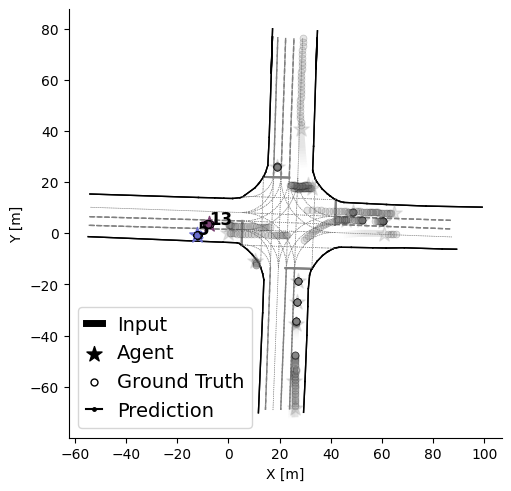

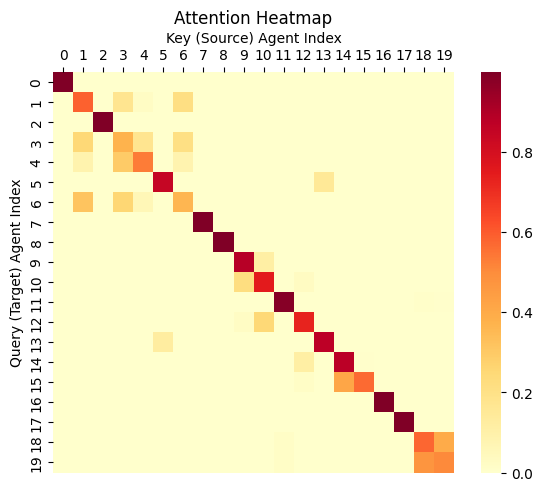

In [26]:
scenario_idx = 2
highlight_idx = [13, 5]  # Sample agents to highlight

fig, ax = plt.subplots(num=30, clear=True, layout="constrained")
plot_scenario(ax, data, pred, scenario_idx=scenario_idx, highlight_idx=highlight_idx)

fig, ax = plt.subplots(num=20, clear=True, layout="constrained")
plot_heatmap(ax, data, attn, scenario_idx=scenario_idx)

Study the heatmap to understand which parts of the input data the model focuses on when making predictions.
The diagonal elements of the heatmap represent the self-attention of each agent, while the off-diagonal elements represent the attention between agents.
An agent (*query*) attends to other agents (*keys*) based on their perceived importance for the prediction.
 
The indices correspond to the agents in the scenario, which are the same as the indices in the plot_scenario function.


### 3.1 Questions and assignments

Your task is to find patterns in the heat map and relate them to the scenario under investigation.
Find examples of agents that are highly attended to and agents that are not attended to.
Use the `plot_scenario` function to visualize the scenario and identify the agents in the heatmap.
- Does the learned attention make sense given the scenario?
    - Search for different interesting scenarios, start with scenarios 2 and 23. Plot the heatmap and identify interesting agents.
- Does it correspond to your intuition of which agents are important for the prediction?
- Discuss your observations


### 3.2 Attention investigation: scenarios 2 and 23

Run after the initial imports and data loader. This cell loads the no-map checkpoint used in section 3, reloads the first batch, and creates scene/heatmap pairs plus attention rankings. All indices are local to each scene. Blue boxes highlight the query-to-key pairs printed in the table. Attention rows are queries and columns are keys; weights are averaged over the four attention heads.



Scenario 2: 20 agents; self-attention median = 0.859
Most attended KEY agents, excluding self-attention:
  agent  3: mean received weight 0.03809
  agent  1: mean received weight 0.03474
  agent  6: mean received weight 0.02654
  agent 18: mean received weight 0.02559
  agent 14: mean received weight 0.02197
Least attended KEY agents, excluding self-attention:
  agent  2: mean received weight 3.041e-12
  agent  7: mean received weight 5.352e-11
  agent 16: mean received weight 7.557e-10
  agent  8: mean received weight 1.294e-08
  agent  0: mean received weight 2.563e-07

Scenario 23: 26 agents; self-attention median = 0.776
Most attended KEY agents, excluding self-attention:
  agent  6: mean received weight 0.03860
  agent 12: mean received weight 0.03019
  agent  4: mean received weight 0.02964
  agent  9: mean received weight 0.02500
  agent  8: mean received weight 0.02323
Least attended KEY agents, excluding self-attention:
  agent  2: mean received weight 9.460e-21
  agent  7: m

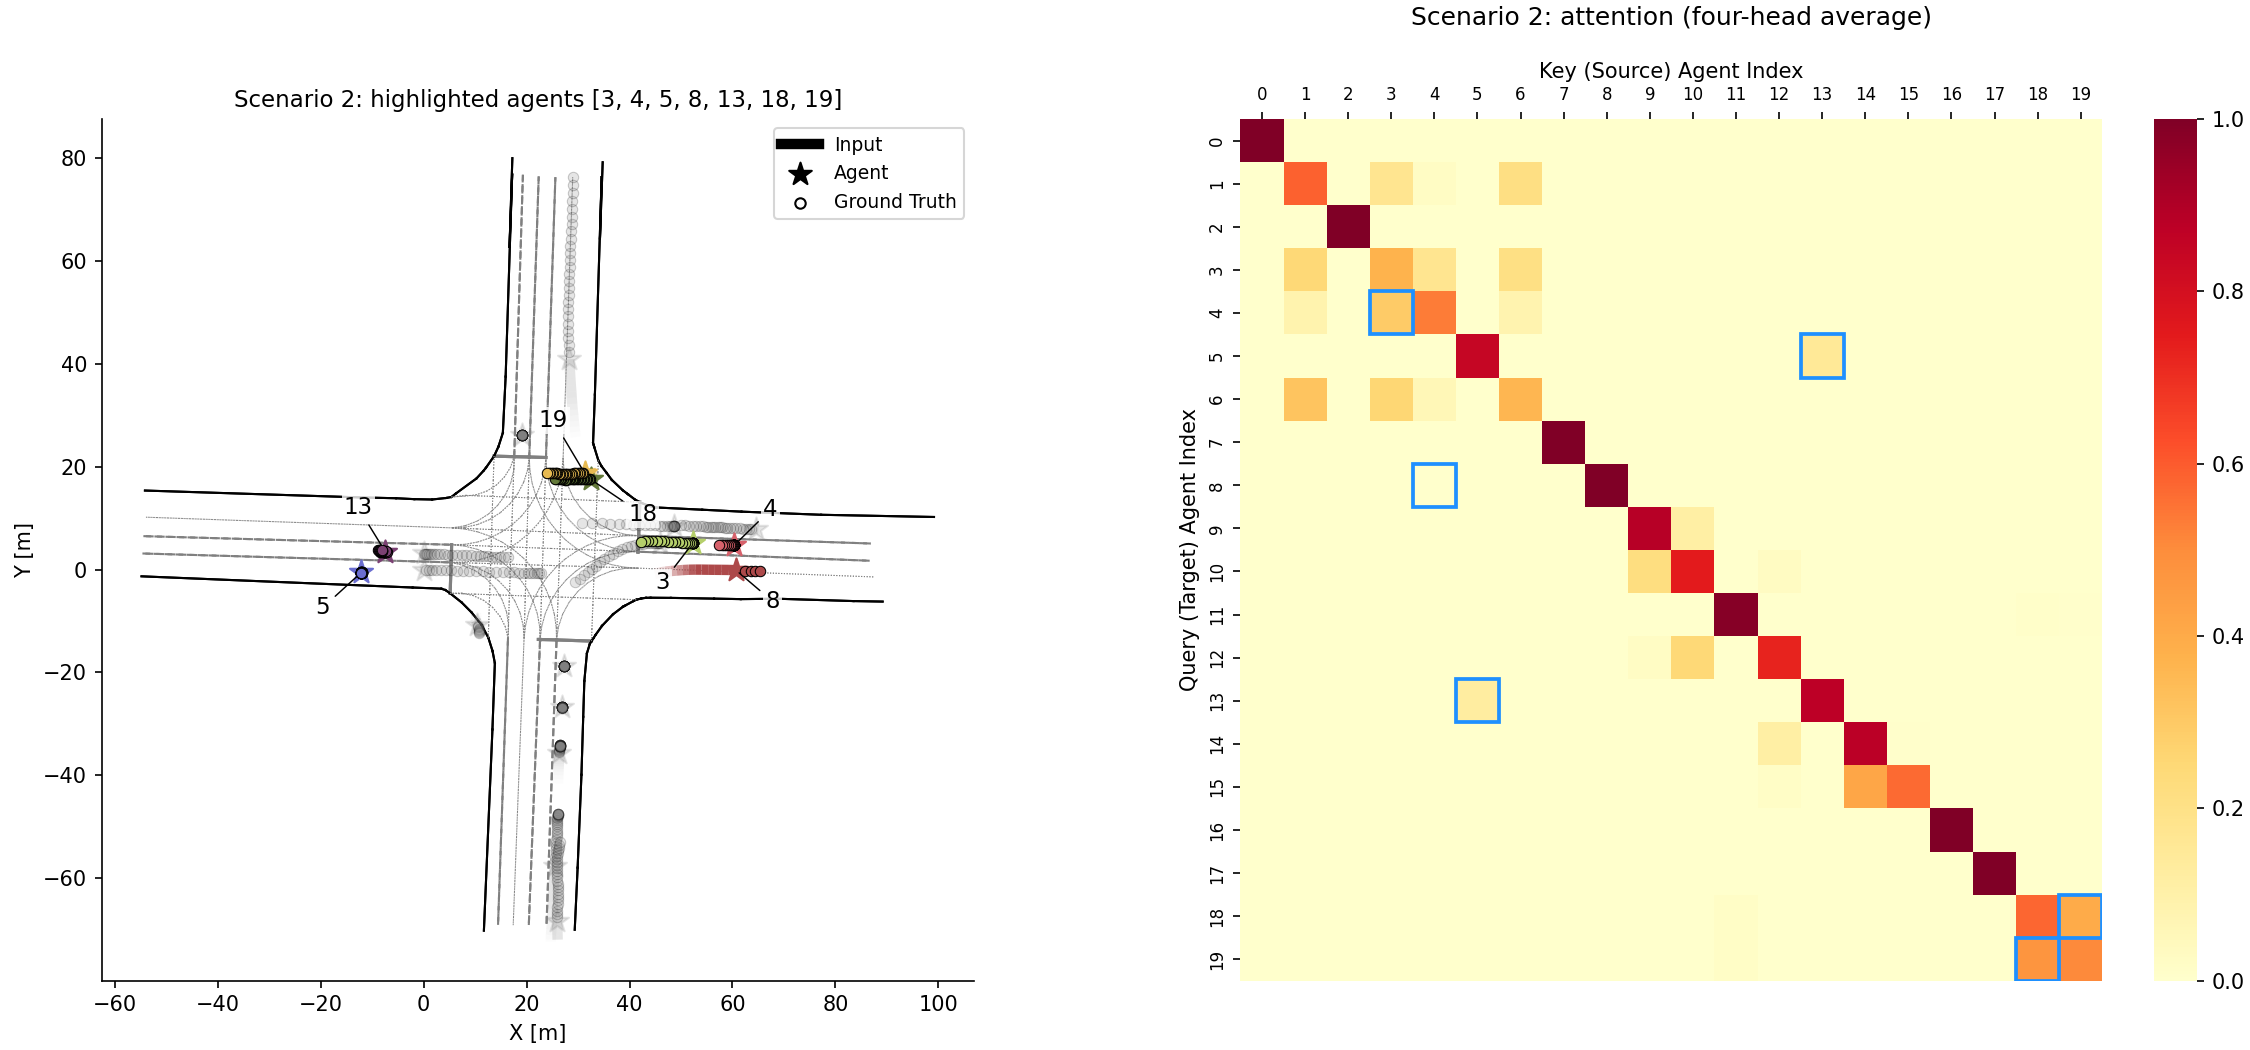

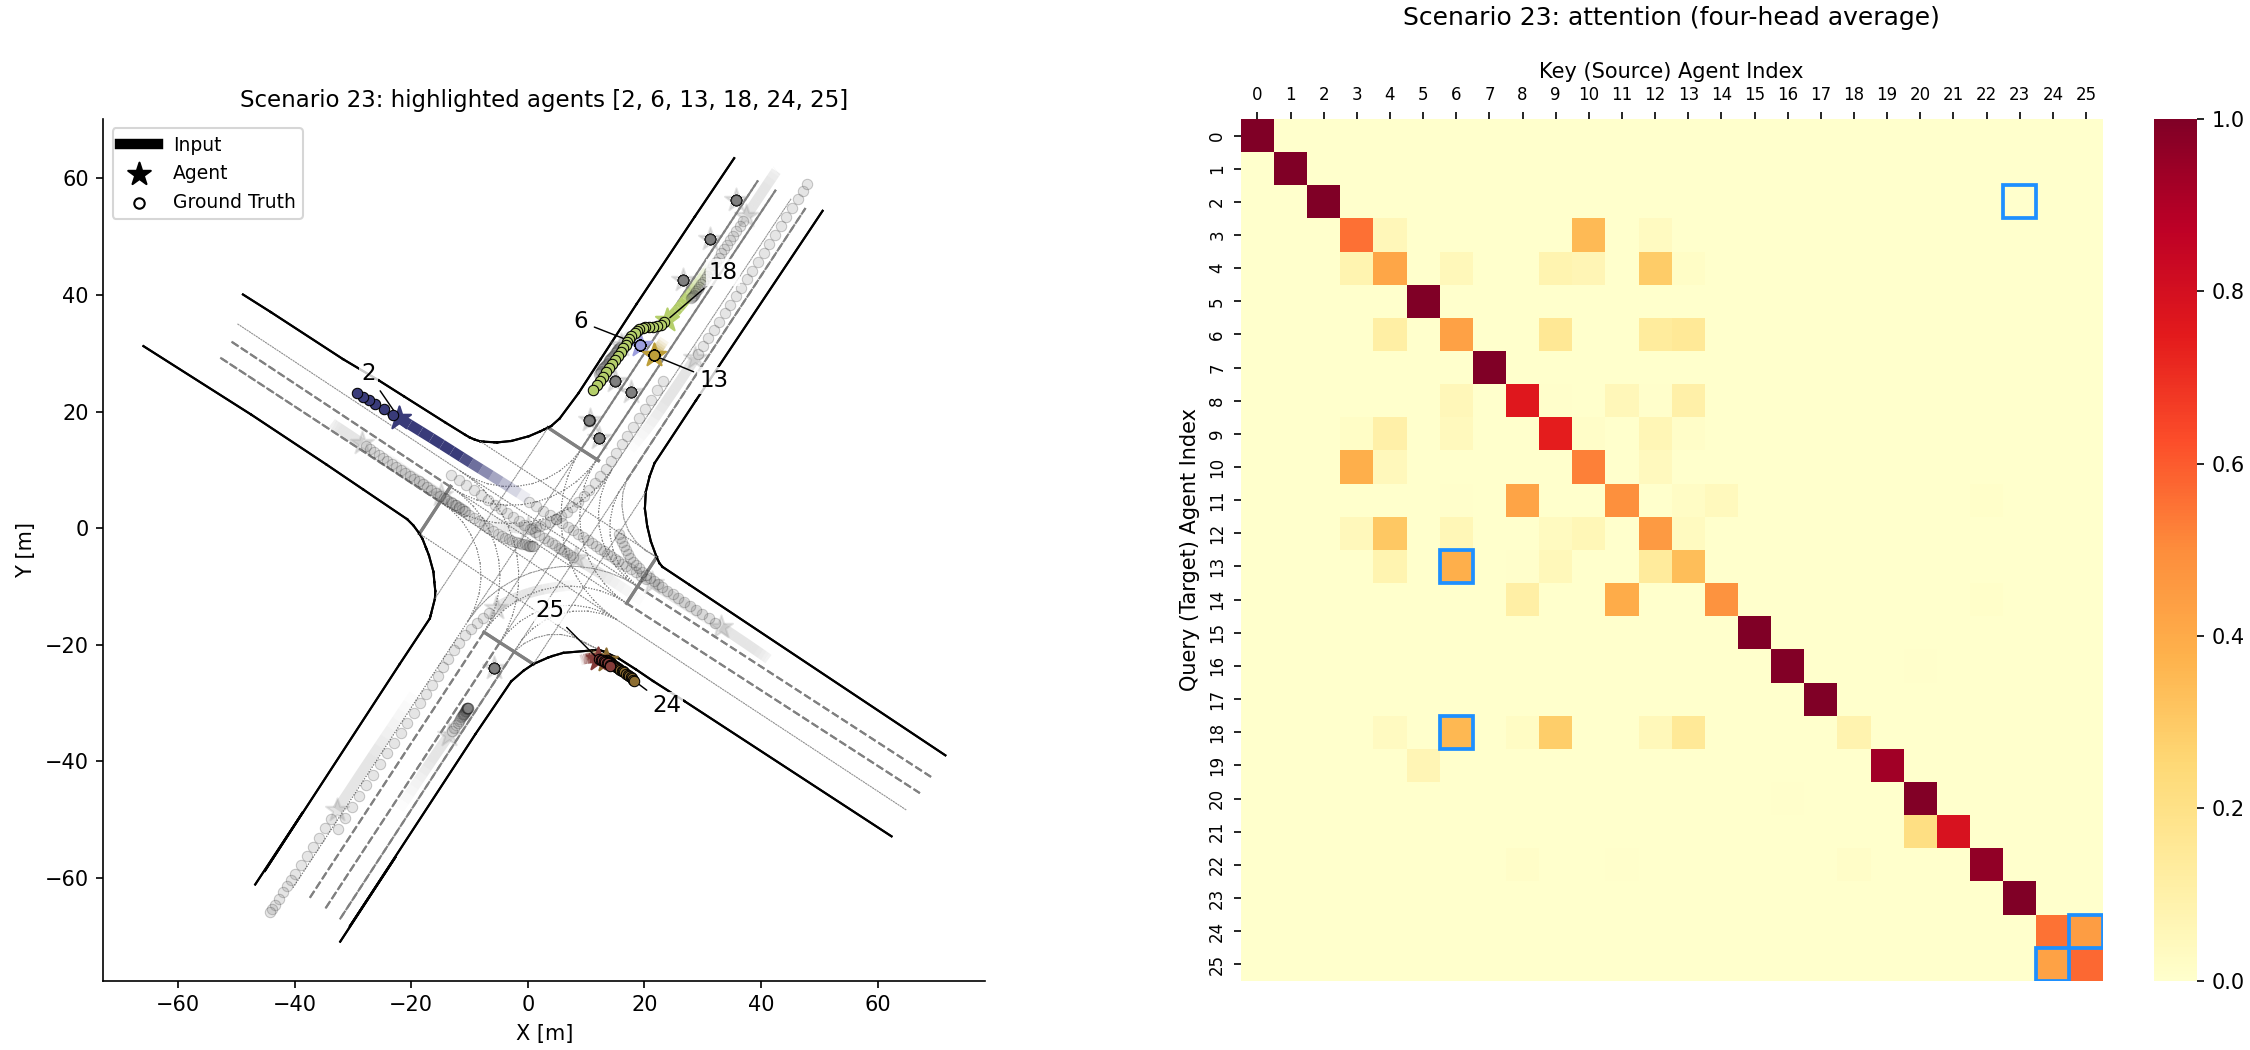

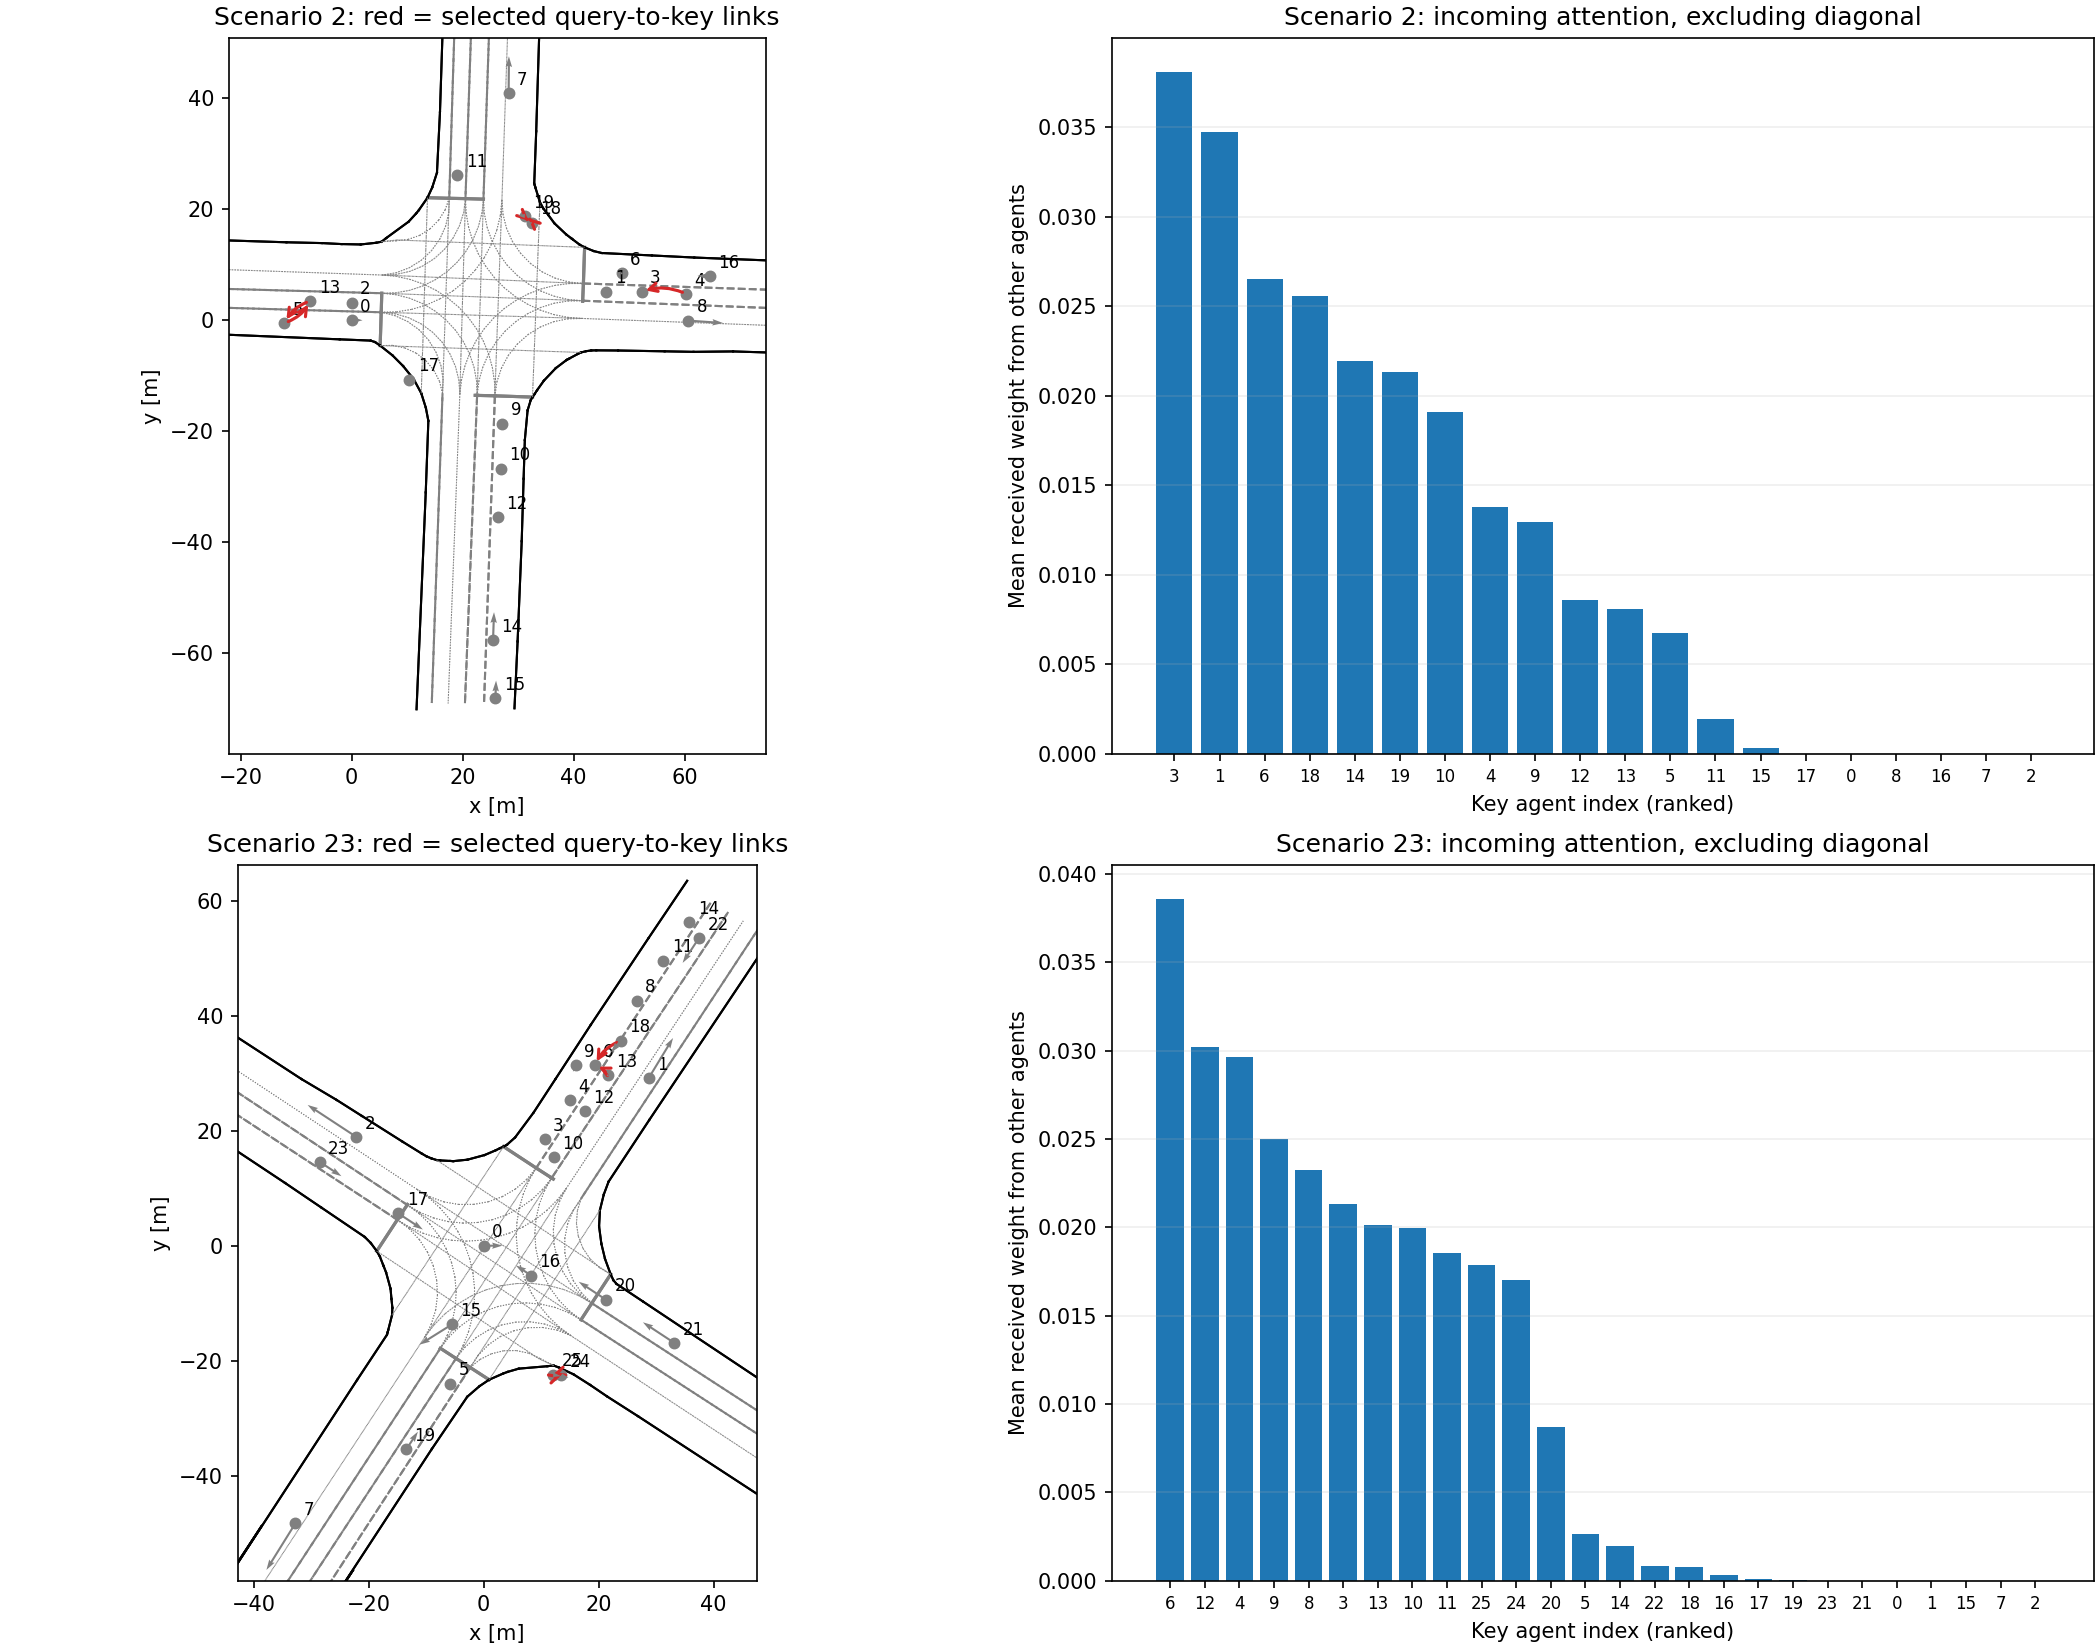

In [ ]:

import time
import platform
import pandas as pd
import numpy as np

from torch_geometric.data import Batch


# Reload the first batch
comparison_data = next(iter(loader)).cpu()

comparison_models = {
    "CV": None,
    "No map": model_nomap.cpu().eval(),
    "MPNN map": model_map.cpu().eval(),
    "GAT map": model_gatmap.cpu().eval()
}

comparison_dir = lab_dir / "model_comparison"
comparison_dir.mkdir(exist_ok=True)



def predict24(name, batch):
    if name == "CV":
        return constant_velocity(batch, 25, STEP_SIZE)

    return comparison_models[name](batch)[1]


def benchmark24(name, batch, repeats=20):
    # Measure CPU inference time in milliseconds
    # Data loading and plotting are excluded

    durations = []

    with torch.no_grad():
        # Warm up the model
        for _ in range(3):
            predict24(name, batch)

        # Measure inference time
        for _ in range(repeats):
            start = time.perf_counter()
            predict24(name, batch)

            elapsed_ms = (time.perf_counter() - start) * 1000
            durations.append(elapsed_ms)

    median = float(np.median(durations))
    p95 = float(np.percentile(durations, 95))

    return median, p95


previous_threads = torch.get_num_threads()
benchmark_threads = 4

timing_rows = []
metric_rows = []
agent_rows = []

comparison_predictions = {}

# Extract scenario 10 as a separate batch
single_scene = Batch.from_data_list(
    [comparison_data.to_data_list()[10]]
)

agents = comparison_data["agent"]

selected_agents = [
    (10, [12, 15, 20]),
    (16, [2])
]



try:
    torch.set_num_threads(benchmark_threads)

    for name, model in comparison_models.items():

        # Generate predictions
        with torch.no_grad():
            prediction = predict24(name, comparison_data)

        # Check prediction shape and values
        assert prediction.shape == agents["trg_pos"].shape
        assert torch.isfinite(prediction).all()

        comparison_predictions[name] = prediction

        # Measure inference time
        batch_ms, batch_p95 = benchmark24(name, comparison_data)
        scene_ms, scene_p95 = benchmark24(name, single_scene)

        # Count model parameters
        parameters = (
            0 if model is None
            else sum(p.numel() for p in model.parameters())
        )

        timing_rows.append({
            "model": name,
            "parameters": parameters,
            "batch_median_ms": batch_ms,
            "batch_p95_ms": batch_p95,
            "scene10_median_ms": scene_ms,
            "scene10_p95_ms": scene_p95
        })

        # Calculate ADE and FDE for the first batch
        ade = MinADE()
        fde = MinFDE()

        ade.update(
            prediction,
            agents["trg_pos"],
            mask=agents["ma_mask"]
        )

        fde.update(
            prediction,
            agents["trg_pos"],
            mask=agents["ma_mask"]
        )

        metric_rows.append({
            "model": name,
            "ADE_m": float(ade.compute()),
            "FDE_m": float(fde.compute())
        })

        # Calculate errors for selected agents
        for scene, agent_ids in selected_agents:

            scene_indices = torch.where(
                agents["batch"] == scene
            )[0]

            for agent_id in agent_ids:
                global_idx = scene_indices[agent_id]

                mask = agents["valid_mask"][global_idx].bool()

                errors = (
                    prediction[global_idx]
                    - agents["trg_pos"][global_idx]
                ).norm(dim=-1)[mask]

                agent_rows.append({
                    "scenario": scene,
                    "agent": agent_id,
                    "model": name,
                    "valid_steps": int(mask.sum()),
                    "ADE_m": float(errors.mean()),
                    "FDE_m": float(errors[-1])
                })

finally:
    # Restore original number of threads
    torch.set_num_threads(previous_threads)



timings24 = pd.DataFrame(timing_rows)
metrics24 = pd.DataFrame(metric_rows)
agents24 = pd.DataFrame(agent_rows)

print(
    f"CPU: {platform.processor()}; "
    f"PyTorch {torch.__version__}; "
    f"{benchmark_threads} threads"
)

print(
    f"Batch: {comparison_data.num_graphs} scenarios, "
    f"{agents.num_nodes} agents"
)

print(
    f"Single scene 10: {single_scene['agent'].num_nodes} agents; "
    "25 predicted steps (5 s)"
)

print(
    "20 measured calls after 3 warmups; "
    "medians and empirical p95 (not worst-case guarantees)."
)

number_format = lambda x: f"{x:.3f}"

print(
    "\nParameters and latency:\n"
    + timings24.to_string(
        index=False,
        float_format=number_format
    )
)

print(
    "\nFIRST batch only, notebook ma_mask:\n"
    + metrics24.to_string(
        index=False,
        float_format=number_format
    )
)

print(
    "\nSelected agents, valid_mask:\n"
    + agents24.to_string(
        index=False,
        float_format=number_format
    )
)

timings24.to_csv(
    comparison_dir / "timings.csv",
    index=False
)

metrics24.to_csv(
    comparison_dir / "batch_metrics.csv",
    index=False
)

agents24.to_csv(
    comparison_dir / "agent_metrics.csv",
    index=False
)


comparison_figures = []

for scene, agent_ids in selected_agents:

    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 10),
        layout="constrained"
    )

    for ax, (name, prediction) in zip(
        axes.flat,
        comparison_predictions.items()
    ):
        plot_scenario(
            ax,
            comparison_data,
            prediction,
            scenario_idx=scene,
            highlight_idx=agent_ids
        )

        ax.set_title(
            f"{name}: scenario {scene}, agents {agent_ids}"
        )

    path = comparison_dir / f"scenario_{scene}_four_models"

    fig.savefig(path.with_suffix(".png"), dpi=140)
    fig.savefig(path.with_suffix(".pdf"))

    comparison_figures.append(path.with_suffix(".png"))

    plt.show()



# 7. Create closeup plots


fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    layout="constrained"
)

model_colors = {
    "CV": "tab:red",
    "No map": "tab:blue",
    "MPNN map": "tab:orange",
    "GAT map": "tab:purple"
}

closeup_agents = [
    (10, 12),
    (10, 15),
    (10, 20),
    (16, 2)
]

for ax, (scene, agent_id) in zip(axes.flat, closeup_agents):

    # Find the selected agent
    scene_indices = torch.where(
        agents["batch"] == scene
    )[0]

    global_idx = scene_indices[agent_id]

    # Get valid history and future positions
    history = agents["inp_pos"][global_idx][
        agents["input_mask"][global_idx]
    ].numpy()

    target = agents["trg_pos"][global_idx][
        agents["valid_mask"][global_idx]
    ].numpy()

    # Plot the map
    plot_scenario_map(ax, comparison_data, scene)

    # Plot observed history
    ax.plot(
        history[:, 0],
        history[:, 1],
        color="black",
        lw=3,
        label="History"
    )

    # Plot ground truth
    ax.plot(
        target[:, 0],
        target[:, 1],
        "o-",
        color="tab:green",
        markersize=3,
        label="Ground truth"
    )

    # Mark the current position
    ax.scatter(
        *history[-1],
        marker="*",
        s=120,
        color="black",
        zorder=10
    )

    all_positions = [history, target]

    # Plot predictions from all four models
    for name, prediction in comparison_predictions.items():

        predicted_positions = prediction[global_idx].numpy()
        all_positions.append(predicted_positions)

        ax.plot(
            predicted_positions[:, 0],
            predicted_positions[:, 1],
            "--",
            color=model_colors[name],
            label=name
        )

        ax.scatter(
            *predicted_positions[-1],
            marker="x",
            color=model_colors[name]
        )

    # Adjust plot limits
    all_positions = np.concatenate(all_positions)

    center = (
        all_positions.min(axis=0)
        + all_positions.max(axis=0)
    ) / 2

    half_width = max(
        np.ptp(all_positions[:, 0]),
        np.ptp(all_positions[:, 1])
    ) / 2 + 4

    ax.set_xlim(
        center[0] - half_width,
        center[0] + half_width
    )

    ax.set_ylim(
        center[1] - half_width,
        center[1] + half_width
    )

    # Format plot
    ax.set_aspect("equal")
    ax.set_title(f"Scenario {scene}, agent {agent_id}")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(fontsize=8)


path = comparison_dir / "selected_agents_closeup"

fig.savefig(path.with_suffix(".png"), dpi=140)
fig.savefig(path.with_suffix(".pdf"))

comparison_figures.append(path.with_suffix(".png"))

plt.show()


### 3.3 Observations and discussion

**How to read the heatmap.** The row is the querying agent and the column is the agent it attends to. Thus A[19,18] describes how agent 19 attends to agent 18, not the reverse. Each row sums to one. Diagonal values are self-attention. The plotted values are averages across four heads; they are neither collision probabilities nor a direct measurement of causal influence. Strong self-attention does not mean that other agents attend strongly to that agent.

For the ranking, received attention is the mean of a column **excluding the diagonal**, divided by the number of other agents in the scene. Graph-masked zeros are included. This is a within-scene descriptive ranking, not an absolute importance or safety score.

**Scenario 2 (20 agents).**

- Agents **3, 1 and 6** receive the highest average attention from other agents (0.03809, 0.03474 and 0.02654). They lie in the nearby, nearly stationary group on the right-hand approach. Agent **4 attends to 3 with weight 0.2946**, at a distance of about **8.06 m**. This is consistent with nearby agents in the same traffic group providing useful information about whether to wait or move, although the weights alone do not establish that this is the learned causal rule.
- Agents **18 and 19** are only **1.71 m** apart and have strong mutual attention: **19 -> 18 = 0.4727** and **18 -> 19 = 0.3987**. Their proximity and related motion make this an intuitively plausible interaction.
- The suggested pair **5 and 13** is also connected: **5 -> 13 = 0.1537**, **13 -> 5 = 0.1287**, at **6.16 m** separation. Both are moving very slowly at the last observed instant. These weights are noticeable, but smaller than for the 18/19 pair.
- Agents **2, 7, 16 and 8** receive very little attention from others. Agent **8 -> 4 is only 0.000314**, despite a separation of **4.83 m** and an allowed graph connection. Agent 8 is moving roughly in the positive x direction while agent 4 is nearly stationary in the adjacent traffic stream. This shows that short distance alone does not determine attention. Agent 8 also has almost all of its own attention on itself; that is a different statement from the low attention it receives from others.

**Scenario 23 (26 agents).**

- Agents **6, 12 and 4** receive the highest average attention from others (0.03860, 0.03019 and 0.02964). They belong to the dense group of nearly stationary agents on the upper-right approach.
- **13 -> 6 = 0.3851** at **2.89 m**, and **18 -> 6 = 0.3565** at **6.18 m**. Agent 6 is nearly stationary; agent 18 is moving toward this group. Attending to nearby agents along the approach agrees with the intuition that the motion of surrounding traffic can constrain the querying agent's future trajectory.
- Agents **24 and 25** form another clear pair: **24 -> 25 = 0.4472**, **25 -> 24 = 0.4258**. They are **1.39 m** apart and have similar velocity directions, making the strong mutual attention plausible.
- Agents **2, 7 and 15** receive almost no attention from others. In particular, **2 -> 23 is approximately 3.27e-16**, although their separation is **7.70 m** and the graph permits the connection. They move in approximately opposite directions along different traffic streams. This is consistent with the network not treating every nearby agent as equally informative, but it does not prove that the ignored agent could never matter.

**Overall patterns and interpretation.**

Both heatmaps have a strong diagonal: median self-attention is approximately **0.859 in scenario 2** and **0.776 in scenario 23**. Many agents therefore rely strongly on their own encoded history. Off-diagonal attention is concentrated in a few nearby pairs or groups, especially among slow/stationary agents. This broadly agrees with the expectation that neighbors in a queue or a shared traffic stream can provide useful context. Attention is also asymmetric: two agents need not rely on one another equally, as shown by 18/19 and 24/25.

There are limits to the interpretation. The network receives encoded position, velocity, acceleration and heading history; attention need not be a simple distance rule. Some near-zero entries result from the proximity graph (50 m radius and capped neighbor selection), while others result from very small learned weights even for permitted connections. The code explicitly verifies graph eligibility for the highlighted pairs, so the low 8 -> 4 and 2 -> 23 weights cannot be explained just by a missing edge.

The selected examples make qualitative sense, but a bright cell does not by itself establish correct reasoning or a correct prediction. The four-head average can hide differences between heads, and other network layers also affect the output. Stronger evidence of an agent's influence would require perturbing or removing it and measuring how predictions change. These figures describe the first batch and the no-map model at the observed instant; they do not establish a general rule for every scene or model.

**Saved results.** The scene/heatmap pairs, geometry/ranking figure and CSV tables are stored in `attention_analysis` next to the notebook. Grey arrows in the geometry figure show one second of the current velocity; red arrows indicate selected query-to-key attention links, not future trajectories.


## 4. Explore and evaluate the different models

In this final part, you should investigate the performance of the different methods. 
The cells below will evaluate the performance for each batch and print out the mean performance across the test data.
This takes a while, could be a few minutes. Therefore, if you set `full_eval` to `False` below, the loop will break after the first batch, which could be helpful if you only want to quickly test the performance. Set `full_eval` to `True` when you collect results for your report. 

Three different performance measures will be evaluated
* average displacement error (ADE),
* final displacement error (FDE)
* miss rate
The ADE measures the average displacement error between the predicted and true positions of the agents, while the FDE measures the displacement error of the agent's final position.

For a full description of the evaluation metrics, see Section IV in the paper "_Toward Unified Practices in Trajectory Prediction Research on Drone Datasets_" 
(https://arxiv.org/abs/2405.00604).

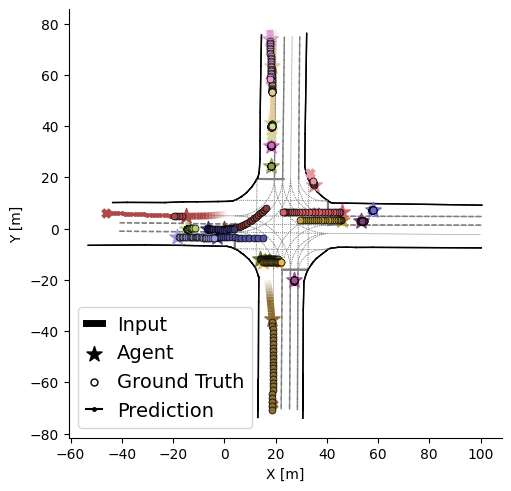

In [27]:
pred_hrz = data["agent"]["trg_pos"].shape[1]  # Prediction horizon (25 steps)
cv_pred = constant_velocity(data, pred_hrz, STEP_SIZE)

fig, ax = plt.subplots(num=40, clear=True, layout="constrained")
plot_scenario(ax, data, cv_pred)

In [48]:
# %% Compare performance between the neural net and the CV model
# Initalize torchmetrics objects for FDE, ADE, and Miss Rate for both ML and CV models
fde_nomap, ade_nomap, miss_rate_nomap = MinFDE(), MinADE(), MissRate()
fde_map, ade_map, miss_rate_map = MinFDE(), MinADE(), MissRate()
fde_gatmap, ade_gatmap, miss_rate_gatmap = MinFDE(), MinADE(), MissRate()
fde_cv, ade_cv, miss_rate_cv = MinFDE(), MinADE(), MissRate()

full_eval = True  # set to 'False' if we only want to study performance over a single batch

import time
import pandas as pd
full_eval_start = time.perf_counter()
previous_eval_threads = torch.get_num_threads()
torch.set_num_threads(4)
eval_counts = {"batches": 0, "scenarios": 0, "scored_agents": 0}
eval_model_seconds = dict.fromkeys(["CV", "No map", "MPNN map", "GAT map"], 0.0)
model_nomap.eval()
model_map.eval()
model_gatmap.eval()
pred_hrz = 25

# Compute ADE and FDE for the neural model predictions
for data in loader:  # Loop over all mini-batches in the test set
    eval_counts["batches"] += 1
    eval_counts["scenarios"] += data.num_graphs
    target_pos = data["agent"]["trg_pos"]
    mask = data["agent"]["ma_mask"]

    eval_counts["scored_agents"] += int(mask.any(dim=1).sum())

    # Constant velocity predictions
    started = time.perf_counter()
    cv_pred = constant_velocity(data, pred_hrz, STEP_SIZE)
    eval_model_seconds["CV"] += time.perf_counter() - started

    # Neural network predictions
    with torch.no_grad():  # Turn of gradients computation
        started = time.perf_counter()
        _, eval_pred, _, _ = model_nomap(data)
        eval_model_seconds["No map"] += time.perf_counter() - started
        started = time.perf_counter()
        _, eval_pred_map, _, _ = model_map(data)
        eval_model_seconds["MPNN map"] += time.perf_counter() - started
        started = time.perf_counter()
        _, eval_pred_gatmap, _, _ = model_gatmap(data)
        eval_model_seconds["GAT map"] += time.perf_counter() - started

    # Update prediction errors for all 4 models
    ade_nomap.update(eval_pred, target_pos, mask=mask)
    fde_nomap.update(eval_pred, target_pos, mask=mask)
    miss_rate_nomap.update(eval_pred, target_pos, mask=mask)

    ade_map.update(eval_pred_map, target_pos, mask=mask)
    fde_map.update(eval_pred_map, target_pos, mask=mask)
    miss_rate_map.update(eval_pred_map, target_pos, mask=mask)

    ade_gatmap.update(eval_pred_gatmap, target_pos, mask=mask)
    fde_gatmap.update(eval_pred_gatmap, target_pos, mask=mask)
    miss_rate_gatmap.update(eval_pred_gatmap, target_pos, mask=mask)

    ade_cv.update(cv_pred, target_pos, mask=mask)
    fde_cv.update(cv_pred, target_pos, mask=mask)
    miss_rate_cv.update(cv_pred, target_pos, mask=mask)

    if eval_counts["batches"] % 25 == 0 or eval_counts["batches"] == len(loader):
        print(f"Evaluated {eval_counts['batches']}/{len(loader)} batches "
              f"({time.perf_counter()-full_eval_start:.1f} s)", flush=True)
    if not full_eval:  # if we only want to study performance over a single batch
        break

ml_ade, ml_fde, ml_mr = ade_nomap.compute(), fde_nomap.compute(), miss_rate_nomap.compute()
ml_map_ade, ml_map_fde, ml_map_mr = ade_map.compute(), fde_map.compute(), miss_rate_map.compute()
ml_gatmap_ade, ml_gatmap_fde, ml_gatmap_mr = ade_gatmap.compute(), fde_gatmap.compute(), miss_rate_gatmap.compute()
cv_ade, cv_fde, cv_mr = ade_cv.compute(), fde_cv.compute(), miss_rate_cv.compute()

print(f"Constant velocity:: ADE: {cv_ade:.2f} m | FDE: {cv_fde:.2f} m | Miss Rate: {cv_mr:.2f}")
print(f"ML model, no map :: ADE: {ml_ade:.2f} m | FDE: {ml_fde:.2f} m | Miss Rate: {ml_mr:.2f}")
print(f"ML model, map    :: ADE: {ml_map_ade:.2f} m | FDE: {ml_map_fde:.2f} m | Miss Rate: {ml_map_mr:.2f}")
print(f"ML model, GAT map:: ADE: {ml_gatmap_ade:.2f} m | FDE: {ml_gatmap_fde:.2f} m | Miss Rate: {ml_gatmap_mr:.2f}")

torch.set_num_threads(previous_eval_threads)
full_eval_seconds = time.perf_counter() - full_eval_start
if full_eval:
    assert eval_counts["batches"] == len(loader)
    assert eval_counts["scenarios"] == len(loader.dataset)
results_full = pd.DataFrame([
    {"model": name, "ADE_m": float(ade), "FDE_m": float(fde),
     "miss_rate": float(mr), "miss_rate_percent": 100*float(mr),
     "prediction_seconds": eval_model_seconds[name]}
    for name, ade, fde, mr in [
        ("CV", cv_ade, cv_fde, cv_mr),
        ("No map", ml_ade, ml_fde, ml_mr),
        ("MPNN map", ml_map_ade, ml_map_fde, ml_map_mr),
        ("GAT map", ml_gatmap_ade, ml_gatmap_fde, ml_gatmap_mr)]
])
print(results_full.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"Coverage: {eval_counts}; total elapsed: {full_eval_seconds:.1f} s")
print("Miss rate: last masked position error > 2 m; metrics pooled over scored agent occurrences.")
evaluation_dir = lab_dir / "full_evaluation"
evaluation_dir.mkdir(exist_ok=True)
results_full.to_csv(evaluation_dir / ("results.csv" if full_eval else "first_batch_results.csv"), index=False)


Evaluated 25/279 batches (15.9 s)
Evaluated 50/279 batches (30.5 s)
Evaluated 75/279 batches (44.4 s)
Evaluated 100/279 batches (58.8 s)
Evaluated 125/279 batches (72.2 s)
Evaluated 150/279 batches (85.8 s)
Evaluated 175/279 batches (99.8 s)
Evaluated 200/279 batches (116.4 s)
Evaluated 225/279 batches (134.7 s)
Evaluated 250/279 batches (153.7 s)
Evaluated 275/279 batches (172.0 s)
Evaluated 279/279 batches (174.1 s)
Constant velocity:: ADE: 1.89 m | FDE: 4.99 m | Miss Rate: 0.51
ML model, no map :: ADE: 1.20 m | FDE: 3.30 m | Miss Rate: 0.46
ML model, map    :: ADE: 1.09 m | FDE: 2.96 m | Miss Rate: 0.44
ML model, GAT map:: ADE: 1.05 m | FDE: 2.86 m | Miss Rate: 0.43
   model  ADE_m  FDE_m  miss_rate  miss_rate_percent  prediction_seconds
      CV 1.8929 4.9890     0.5065            50.6482              0.1193
  No map 1.1993 3.3030     0.4566            45.6628             10.3764
MPNN map 1.0899 2.9616     0.4422            44.2157             35.0011
 GAT map 1.0492 2.8582     0.4

### 4.1 Questions for the model evaluations

In your report, reflect on the various metrics used in the assignment and evaluate the overall performance of the models. Consider addressing the following questions:

- What do the different displacement metrics measure? Are both of them necessary?
- How do the various methods compare? Is the performance difference significant?
- How does the improved performance of ML-based approaches affect overall runtime? Is their use justified?
- Does incorporating map-based information improve performance? Why or why not?
